# TrDPNet · De una imagen a una nube de puntos 3D
* Maestría en Inteligencia Artificial y Ciencia de Datos
* Inferencia con una arquitectura Transformer encoder–decoder
* Procesamiento de Datos Secuenciales
* ### Estudiante: Julián René Muñoz Burbano
* ### Docente: PhD(c). Natali Johana Velandia Fajardo

| | |
|---|---|
| **Artículo base** | F. Li, T. Li, K. Xiao, L. Wang, L. Yu, *TrDPNet: A transformer-based diffusion model for single-image 3D point cloud reconstruction*, J. Vis. Commun. Image R. 111 (2025) 104503 |
| **Código original** | https://github.com/TLab512/TrDPNet |
| **Repositorio del proyecto** | https://github.com/JulianReneMunoz/TrDPNet |

## Contenido

| Punto evaluado | Sección |
|---|---|
| Datos secuenciales y problema | 2 · Análisis exploratorio (EDA) |
| Pesos preentrenados e inferencia | 3 · Modelo y pesos |
| Entradas y salidas del modelo | 4 · Entradas y salidas |
| Arquitectura en detalle | 5 · Arquitectura |
| Mecanismo de atención y tensores Q, K, V | 6 · Atención |
| Innovaciones del modelo | 7 · Innovación |
| Inferencia funcional con visualización | 8 · Inferencia y resultados |
| Carga de datos e interfaz interactiva | 9 · Interfaz |
| Limitaciones | 10 · Cierre y banco de preguntas |

# 1 · Preparación del entorno

**Qué hace:** importa las librerías, elige GPU o CPU, crea las carpetas de salida y define dos herramientas que se usan en todo el notebook: `tarjeta()`, que presenta cada resultado de forma ordenada, y `anima()`, que convierte un proceso en una animación reproducible.

**Detalle importante:** si ya existe el archivo de pesos `weights/trdpnet_replica.pt`, la configuración del modelo **se lee del propio archivo**. Así los datos, la arquitectura y los pesos quedan siempre sincronizados.

**Interruptores:**
- `EVALUACION_COMPLETA = True` recalcula todas las métricas (tarda varios minutos). Con `False` se muestran las métricas guardadas en la última ejecución completa: es el modo recomendado **durante la sustentación**.
- `ANIMACIONES = False` desactiva las animaciones si se necesita máxima velocidad.

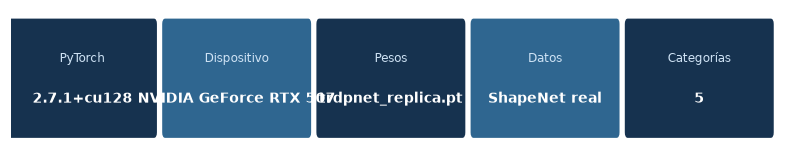

In [1]:
# =============================================================================
# 1 · PREPARACIÓN DEL ENTORNO
# =============================================================================
import os, sys, json, math, time, random, shutil, inspect
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle, Circle
from IPython.display import HTML, display

EVALUACION_COMPLETA = True      # False durante la sustentación (usa las métricas guardadas)
ANIMACIONES = True              # False para máxima velocidad
SMOKE = os.environ.get("TRDPNET_SMOKE", "0") == "1"      # uso interno: prueba rápida

BASE = Path.cwd()
FIG = BASE / "latex" / "figuras"          # las figuras van directo a la carpeta del informe
for d in ["weights", "outputs", "outputs/animaciones", "outputs/interfaz", "latex/figuras", "streamlit_app"]:
    (BASE / d).mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": .25,
                     "figure.facecolor": "white", "animation.embed_limit": 100})

# --- dispositivo ---------------------------------------------------------------
FORZAR_CPU = os.environ.get("TRDPNET_FORCE_CPU", "0") == "1"
DEVICE = torch.device("cuda" if (not FORZAR_CPU and torch.cuda.is_available()) else "cpu")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# --- dónde están los datos reales y los pesos ---------------------------------
USAR_DATASET_REAL = True        # False fuerza el banco sintético de respaldo
VISTAS_POR_MODELO = 2           # imágenes distintas que se aprovechan de cada modelo 3D
N_TRAIN_POR_CAT, N_TEST_POR_CAT = 80, 12
PASOS_REAL, PASOS_AJUSTE = 4000, 1200    # pasos si se entrena desde cero / si solo se ajustan los pesos

SYNSET = {"02691156": "avion", "02828884": "banca", "02933112": "armario", "02958343": "auto",
          "03001627": "silla", "03211117": "pantalla", "03636649": "lampara", "03691459": "parlante",
          "04090263": "rifle", "04256520": "sofa", "04379243": "mesa", "04401088": "telefono",
          "04530566": "embarcacion"}          # las 13 categorías de ShapeNet-R2N2

RUTAS_SHAPENET = [Path(os.environ.get("TRDPNET_SHAPENET", "__sin_definir__")),
                  Path(r"C:\Users\PersonalJR\Documents\Python Scripts\ISR_ONET_HD_EG3D\data\ShapeNet"),
                  BASE / "data" / "ShapeNet",
                  BASE.parent / "ISR_ONET_HD_EG3D" / "data" / "ShapeNet"]
RUTAS_PESOS = [Path(os.environ.get("TRDPNET_PESOS", "__sin_definir__")),
               BASE / "weights" / "trdpnet_shapenet.pt",
               BASE / "weights" / "trdpnet_replica.pt",
               Path(r"C:\Users\PersonalJR\Documents\Python Scripts\TrDPNet_entrega_v3\weights\trdpnet_replica.pt"),
               Path(r"C:\Users\PersonalJR\Documents\Python Scripts\TrDPNet\weights\trdpnet_replica.pt")]
RUTA_SHAPENET = next((p for p in RUTAS_SHAPENET if p.exists()), None)
SALIDA_PESOS = BASE / "weights" / "trdpnet_shapenet.pt"     # pesos adaptados al conjunto real
RUTA_PESOS = next((p for p in RUTAS_PESOS if p.exists()), SALIDA_PESOS)
if SMOKE:
    N_TRAIN_POR_CAT, N_TEST_POR_CAT, VISTAS_POR_MODELO = 3, 2, 1
    PASOS_REAL, PASOS_AJUSTE = 10, 6

# --- configuración: la del checkpoint si existe; si no, la de referencia --------
CFG_REFERENCIA = dict(
    modo="rapido", seed=42, categorias=["avion", "silla", "mesa", "lampara", "sofa"],
    n_puntos=1024, img_size=48, patch=8, n_train_por_cat=40, n_test_por_cat=8,
    dim=128, depth=4, heads=4, img_depth=2, M_centros=64, K_vecinos=24, radio=0.22,
    T=200, beta_0=8.5e-4, beta_T=1.2e-2, warmup=0.10, p_uncond=0.10, omega=3.0,
    pasos=1500, batch=16, lr=3e-4, weight_decay=0.01, tau=0.05, n_eval_por_cat=3,
    omegas_ablacion=[1.0, 2.0, 3.0, 5.0], ablacion_self_attention=False)
if SMOKE:
    CFG_REFERENCIA.update(n_puntos=256, dim=64, M_centros=24, K_vecinos=12, img_size=32, pasos=12,
                          batch=4, T=20, n_train_por_cat=3, n_test_por_cat=2, n_eval_por_cat=1,
                          omegas_ablacion=[1.0, 3.0])

if RUTA_PESOS.exists():
    CFG = torch.load(RUTA_PESOS, map_location="cpu", weights_only=False)["cfg"]
    origen_cfg = f"leída del checkpoint {RUTA_PESOS.name}"
else:
    CFG = dict(CFG_REFERENCIA)
    origen_cfg = "de referencia (aún no hay pesos: se prepararán en la sección 3)"
CATS = CFG["categorias"]
N_FRAMES = 8 if SMOKE else 24

# --- herramienta 1: tarjeta de resultados ------------------------------------
def tarjeta(titulo, muestra, analisis, interpretacion, sustentacion=None):
    '''Presenta un resultado en tres bloques: qué muestra, análisis e interpretación.'''
    li = lambda xs: "".join(f"<li style='margin:3px 0'>{x}</li>" for x in xs)
    pie = (f"<div style='padding:8px 14px;background:#1f3b57;color:#fff'>🎤 <b>Para la sustentación:</b> "
           f"{sustentacion}</div>") if sustentacion else ""
    html = f'''
<div style="border:1px solid #c9d3dd;border-radius:10px;margin:10px 0;overflow:hidden;
            font-family:Segoe UI,Arial,sans-serif;font-size:13px;line-height:1.4">
  <div style="background:#16324f;color:#fff;padding:8px 14px;font-weight:600;font-size:14px">{titulo}</div>
  <div style="display:grid;grid-template-columns:1fr 1.2fr 1.2fr">
    <div style="padding:10px 14px;background:#eaf2fb"><b>📊 Qué muestra</b><p style="margin:6px 0">{muestra}</p></div>
    <div style="padding:10px 14px;background:#fff7e3"><b>🔎 Análisis</b><ul style="padding-left:18px;margin:6px 0">{li(analisis)}</ul></div>
    <div style="padding:10px 14px;background:#e9f6ec"><b>💡 Interpretación</b><ul style="padding-left:18px;margin:6px 0">{li(interpretacion)}</ul></div>
  </div>{pie}
</div>'''
    display(HTML(html))

# --- herramienta 2: animaciones ----------------------------------------------
def anima(fig, actualiza, n_frames, nombre, fps=8):
    '''Genera la animación, la guarda como GIF y la incrusta con controles de reproducción.'''
    if not ANIMACIONES:
        plt.close(fig); print(f"[animación '{nombre}' desactivada]"); return
    ani = animation.FuncAnimation(fig, actualiza, frames=n_frames, interval=int(1000 / fps))
    try:
        ani.save(BASE / "outputs/animaciones" / f"{nombre}.gif", writer=animation.PillowWriter(fps=fps), dpi=80)
    except Exception as e:
        print("GIF no guardado (instale pillow):", type(e).__name__)
    display(HTML(ani.to_jshtml(fps=fps))); plt.close(fig)

def guarda(nombre):
    plt.savefig(FIG / f"{nombre}.png", bbox_inches="tight", dpi=130)

# --- resumen visual del entorno ------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 1.6)); ax.axis("off")
items = [("PyTorch", torch.__version__),
         ("Dispositivo", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU"),
         ("Pesos", RUTA_PESOS.name if RUTA_PESOS.exists() else "pendientes"),
         ("Datos", "ShapeNet real" if (RUTA_SHAPENET and USAR_DATASET_REAL) else "banco sintético"),
         ("Categorías", str(len(CATS)))]
for i, (k, v) in enumerate(items):
    ax.add_patch(FancyBboxPatch((i * 2.05, .1), 1.9, .8, boxstyle="round,pad=.04",
                                fc="#16324f" if i % 2 == 0 else "#2f6690", ec="none"))
    ax.text(i * 2.05 + .95, .62, k, ha="center", color="#cfe3f5", fontsize=8)
    ax.text(i * 2.05 + .95, .32, v[:22], ha="center", color="white", fontsize=9, weight="bold")
ax.set_xlim(0, 10.2); ax.set_ylim(0, 1); plt.show()

tarjeta("1 · Entorno listo",
        f"Versión de las librerías, el dispositivo de cálculo y el estado del archivo de pesos. "
        f"La configuración es <b>{origen_cfg}</b>.",
        [f"Dispositivo de cálculo: <b>{DEVICE}</b>.",
         f"Modelo: {CFG['depth']} bloques Transformer, dimensión {CFG['dim']}, {CFG['heads']} cabezas.",
         f"Nube de {CFG['n_puntos']} puntos, imagen de {CFG['img_size']}×{CFG['img_size']} px, T = {CFG['T']} pasos.",
         (f"Conjunto real localizado en <code>{RUTA_SHAPENET}</code>." if RUTA_SHAPENET
          else "No se localizó ShapeNet: se usará el banco sintético de respaldo.")],
        ["Leer la configuración desde el checkpoint evita el error más común: cargar pesos en una "
         "arquitectura con dimensiones distintas.",
         "Las rutas se buscan en una lista de candidatas; basta con añadir la propia al principio de "
         "<code>RUTAS_SHAPENET</code> o <code>RUTAS_PESOS</code> si el proyecto se mueve de carpeta.",
         "En GPU la inferencia completa de un objeto tarda pocos segundos; en CPU, del orden de un minuto."],
        "La configuración viaja dentro del archivo de pesos; por eso el modelo siempre se reconstruye igual.")

# 2 · Datos y análisis exploratorio (EDA)

## ¿Por qué una nube de puntos es un dato secuencial?

* Una nube de puntos es una **secuencia de N vectores (x, y, z)** sin orden natural: reordenar los puntos no cambia el objeto. 

* Es el mismo tipo de estructura que una frase para un Transformer de lenguaje, con una diferencia clave: aquí el orden no existe. 

* La auto-atención es **invariante a permutaciones**, por lo que encaja de forma natural con este tipo de dato.

## El conjunto de datos: ShapeNet-R2N2 real

Se emplea el **mismo conjunto del artículo**: el subconjunto de 13 categorías de ShapeNet definido por 3D-R2N2, con las nubes de puntos y las vistas renderizadas ya preprocesadas. Cada modelo 3D aporta:

| Archivo | Contenido | Uso en el proyecto |
|---|---|---|
| `pointcloud.npz` | nube densa del objeto con `loc` y `scale` | objetivo que el modelo debe reconstruir |
| `img_choy2016/*.jpg` | 24 vistas renderizadas del mismo objeto | entrada: **una sola** de esas vistas |
| `img_choy2016/cameras.npz` | matrices de cámara de cada vista | alinear la nube con la vista elegida |

El lector escrito en la celda siguiente **detecta solo el formato disponible**: acepta `.npz`, `.ply`, `.npy`, `.obj` y `.binvox` para la geometría, y `.jpg`/`.png` con o sin canal alfa para las vistas. Cuando existen matrices de cámara, la nube se lleva al sistema de la vista para que imagen y geometría correspondan; cuando no existen, la imagen se rehace proyectando la propia nube real. Si no se localiza el conjunto, se recurre a un banco sintético de respaldo con el mismo formato, de modo que el notebook **siempre se ejecuta**.

Esta celda define las funciones de datos y construye el conjunto de prueba. Las celdas siguientes lo exploran desde seis ángulos.

In [2]:
# =============================================================================
# 2.0 · LECTURA DEL CONJUNTO: ShapeNet real (con banco sintético de respaldo)
# =============================================================================
# ---- banco sintético de respaldo (idéntico al de la versión anterior) ---------
def _caja(n, cx, cy, cz, sx, sy, sz, rng):
    '''Puntos sobre la superficie de una caja (no en su interior).'''
    p = rng.uniform(-0.5, 0.5, size=(n, 3)) * np.array([sx, sy, sz])
    eje = rng.integers(0, 3, size=n); signo = rng.choice([-0.5, 0.5], size=n)
    for a in range(3):
        m = eje == a
        p[m, a] = signo[m] * [sx, sy, sz][a]
    return p + np.array([cx, cy, cz])

def _cilindro(n, cx, cy, cz, r, h, rng, eje=1):
    '''Puntos sobre el manto de un cilindro alineado a un eje.'''
    th = rng.uniform(0, 2 * np.pi, n); hh = rng.uniform(-h / 2, h / 2, n)
    a, b = r * np.cos(th), r * np.sin(th)
    p = {0: np.stack([hh, a, b], 1), 1: np.stack([a, hh, b], 1), 2: np.stack([a, b, hh], 1)}[eje]
    return p + np.array([cx, cy, cz])

def genera_forma(cat, n, rng):
    '''Devuelve una nube (n,3) normalizada de la categoría pedida.'''
    if cat == "avion":
        L, W = rng.uniform(0.9, 1.15), rng.uniform(0.8, 1.25)
        partes = [_cilindro(int(n * .35), 0, 0, 0, 0.06, L, rng, eje=2),          # fuselaje
                  _caja(int(n * .35), 0, 0, 0.0, W, 0.02, 0.25, rng),             # alas
                  _caja(int(n * .15), 0, 0, -L / 2 + .1, 0.42, 0.02, 0.15, rng),  # estabilizador
                  _caja(int(n * .15), 0, .12, -L / 2 + .1, 0.02, 0.26, 0.15, rng)]# deriva
    elif cat == "silla":
        h, w = rng.uniform(0.5, 0.8), rng.uniform(0.45, 0.62)
        partes = [_caja(int(n * .30), 0, 0, 0, w, 0.05, w, rng),                  # asiento
                  _caja(int(n * .30), 0, h / 2, -w / 2, w, h, 0.05, rng)]         # respaldo
        for dx in (-1, 1):
            for dz in (-1, 1):
                partes.append(_cilindro(int(n * .10), dx * w / 2 * .85, -.25, dz * w / 2 * .85, .03, .5, rng))
    elif cat == "mesa":
        w, d, h = rng.uniform(0.8, 1.15), rng.uniform(0.5, 0.85), rng.uniform(0.4, 0.62)
        partes = [_caja(int(n * .40), 0, 0, 0, w, 0.06, d, rng)]                  # tablero
        for dx in (-1, 1):
            for dz in (-1, 1):
                partes.append(_cilindro(int(n * .15), dx * w / 2 * .9, -h / 2, dz * d / 2 * .85, .035, h, rng))
    elif cat == "lampara":
        h, r = rng.uniform(0.6, 0.95), rng.uniform(0.25, 0.42)
        th = rng.uniform(0, 2 * np.pi, int(n * .45)); u = rng.uniform(0, 1, int(n * .45))
        pantalla = np.stack([r * u * np.cos(th), h / 2 + .25 * (1 - u), r * u * np.sin(th)], 1)
        partes = [pantalla,
                  _cilindro(int(n * .35), 0, 0, 0, .03, h, rng),                  # vástago
                  _cilindro(int(n * .20), 0, -h / 2, 0, .22, .04, rng)]           # base
    else:  # sofa
        w, d = rng.uniform(0.9, 1.25), rng.uniform(0.5, 0.68)
        partes = [_caja(int(n * .35), 0, 0, 0, w, .25, d, rng),
                  _caja(int(n * .25), 0, .25, -d / 2, w, .5, .12, rng),
                  _caja(int(n * .20), -w / 2, .15, 0, .12, .4, d, rng),
                  _caja(int(n * .20),  w / 2, .15, 0, .12, .4, d, rng)]
    pts = np.concatenate(partes, 0)
    if len(pts) < n:                                   # completar por remuestreo
        pts = np.concatenate([pts, pts[rng.integers(0, len(pts), n - len(pts))]], 0)
    pts = pts[rng.permutation(len(pts))[:n]]
    pts -= pts.mean(0, keepdims=True)                  # centrar
    pts /= (np.abs(pts).max() + 1e-8) / 0.5            # escalar al cubo [-0.5, 0.5]
    return pts.astype(np.float32)

DIST_CAM, FOCAL = 2.0, 1.6
def base_camara(elev_deg, azim_deg):
    '''Devuelve la matriz de rotación mundo->cámara (3x3).'''
    e, a = np.radians(elev_deg), np.radians(azim_deg)
    frente = np.array([np.cos(e) * np.sin(a), np.sin(e), np.cos(e) * np.cos(a)])
    arriba = np.array([0.0, 1.0, 0.0])
    derecha = np.cross(frente, arriba); derecha /= np.linalg.norm(derecha)
    arriba2 = np.cross(derecha, frente)
    return np.stack([derecha, arriba2, frente], 0)

def renderiza(points, img=None, elev=20.0, azim=35.0):
    '''Nube (N,3) -> imagen de profundidad (1,H,W) en [0,1]. 0 = fondo.'''
    img = img or CFG["img_size"]
    cam = points @ base_camara(elev, azim).T
    z = cam[:, 2] + DIST_CAM
    u = (cam[:, 0] / z) * FOCAL
    v = (cam[:, 1] / z) * FOCAL
    ix = np.clip(((u + 0.5) * img).astype(int), 0, img - 1)
    iy = np.clip(((0.5 - v) * img).astype(int), 0, img - 1)
    prof = np.full((img, img), np.inf)
    np.minimum.at(prof, (iy, ix), z)          # z-buffer: el punto más cercano gana
    m = np.isfinite(prof)
    out = np.zeros((img, img), np.float32)
    if m.any():
        d = prof[m]
        out[m] = 1.0 - (d - d.min()) / (d.max() - d.min() + 1e-8) * 0.7
    return out[None].astype(np.float32)

def construye_conjunto(n_por_cat, seed):
    rng = np.random.default_rng(seed)
    P, I, Y = [], [], []
    for ci, c in enumerate(CATS):
        for _ in range(n_por_cat):
            pc = genera_forma(c, CFG["n_puntos"], rng)
            im = renderiza(pc, elev=rng.uniform(15, 25), azim=rng.uniform(20, 50))
            P.append(pc); I.append(im); Y.append(ci)
    return np.stack(P), np.stack(I), np.array(Y)

# ---- lectores del conjunto real ----------------------------------------------
IMG_EXT = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
CONVENCIONES = [(sg, od) for od in [(0, 1, 2), (0, 2, 1)]
                for sg in [(1, 1, 1), (1, -1, 1), (-1, 1, 1), (-1, -1, 1)]]
def detecta_dataset(ruta):
    '''Localiza la raíz que contiene las carpetas de categoría (synsets) de ShapeNet.

    Acepta tanto la carpeta ShapeNet como una categoría concreta (por ejemplo 02691156).
    Devuelve (raiz, {nombre_en_español: carpeta}).'''
    if ruta is None:
        return None, {}
    p = Path(ruta)
    if not p.exists():
        return None, {}
    if p.name in SYNSET:                      # se apuntó directamente a una categoría
        p = p.parent
    def _cats(d):
        return {SYNSET[x.name]: x for x in sorted(d.iterdir()) if x.is_dir() and x.name in SYNSET}
    c = _cats(p)
    if c:
        return p, c
    for sub in sorted(x for x in p.iterdir() if x.is_dir()):   # un nivel más abajo
        c = _cats(sub)
        if c:
            return sub, c
    return None, {}

def modelos_de(cat_dir, split="train", limite=None, salto=0):
    '''Lista las carpetas de modelo de una categoría respetando train.lst / test.lst si existen.'''
    lst = cat_dir / f"{'test' if split == 'test' else 'train'}.lst"
    if lst.exists():
        ids = [l.strip() for l in lst.read_text(encoding="utf-8", errors="ignore").splitlines() if l.strip()]
        dirs = [cat_dir / i for i in ids if (cat_dir / i).is_dir()]
    else:
        dirs = sorted(d for d in cat_dir.iterdir() if d.is_dir())
        corte = max(1, int(len(dirs) * 0.8))
        dirs = dirs[:corte] if split != "test" else dirs[corte:] or dirs[-max(1, len(dirs) // 5):]
    dirs = dirs[salto:]
    return dirs[:limite] if limite else dirs

def _de_npz(f):
    '''Nube desde .npz (formato Occupancy Networks u otros).'''
    z = np.load(f, allow_pickle=False)
    claves = list(z.keys())
    k = next((c for c in ["points", "point_cloud", "pointcloud", "pts", "arr_0"] if c in claves), None)
    if k is None:
        return None
    p = np.asarray(z[k], np.float32)
    if p.ndim == 3:
        p = p.reshape(-1, p.shape[-1])
    if p.ndim != 2 or p.shape[1] != 3:
        return None
    if "occupancies" in claves:               # points.npz: solo interesan los puntos ocupados
        occ = np.asarray(z["occupancies"])
        if occ.dtype == np.uint8 and occ.size * 8 >= len(p):
            occ = np.unpackbits(occ)[:len(p)]
        occ = occ.astype(bool)[:len(p)]
        if occ.any():
            p = p[occ]
    if "loc" in claves and "scale" in claves:  # convención Occupancy Networks
        p = p * float(np.asarray(z["scale"]).ravel()[0]) + np.asarray(z["loc"], np.float32).ravel()[:3]
    return p

def _de_ply(f):
    '''Nube desde .ply (ascii o binary_little_endian).'''
    raw = Path(f).read_bytes()
    fin = raw.find(b"end_header")
    if fin < 0:
        return None
    cab = raw[:fin].decode("ascii", "ignore").splitlines()
    ini = raw.find(b"\n", fin) + 1
    fmt = next((l.split()[1] for l in cab if l.startswith("format")), "ascii")
    n, props, leyendo = 0, [], False
    tam = {"float": 4, "float32": 4, "double": 8, "float64": 8, "uchar": 1, "uint8": 1, "char": 1, "int8": 1,
           "short": 2, "ushort": 2, "int": 4, "uint": 4, "int32": 4, "uint32": 4}
    tipo = {"float": "f4", "float32": "f4", "double": "f8", "float64": "f8", "uchar": "u1", "uint8": "u1",
            "char": "i1", "int8": "i1", "short": "i2", "ushort": "u2", "int": "i4", "uint": "u4",
            "int32": "i4", "uint32": "u4"}
    for l in cab:
        t = l.split()
        if not t:
            continue
        if t[0] == "element":
            leyendo = t[1] == "vertex"
            if leyendo:
                n = int(t[2])
        elif t[0] == "property" and leyendo and t[1] != "list":
            props.append((t[2], t[1]))
    if n == 0 or not props:
        return None
    nombres = [p[0] for p in props]
    if not {"x", "y", "z"} <= set(nombres):
        return None
    if fmt.startswith("ascii"):
        cuerpo = raw[ini:].decode("ascii", "ignore").split()
        arr = np.array(cuerpo[:n * len(props)], np.float32).reshape(n, len(props))
    else:
        dt = np.dtype([(p[0], ("<" if "little" in fmt else ">") + tipo.get(p[1], "f4")) for p in props])
        arr = np.frombuffer(raw[ini:ini + n * dt.itemsize], dt)
        arr = np.stack([arr[c].astype(np.float32) for c in nombres], 1)
    idx = [nombres.index(c) for c in ("x", "y", "z")]
    return arr[:, idx].astype(np.float32)

def _de_obj(f, n, rng):
    '''Nube muestreada sobre la superficie de una malla .obj (muestreo proporcional al área).'''
    V, Fa = [], []
    for l in Path(f).read_text(encoding="utf-8", errors="ignore").splitlines():
        if l.startswith("v "):
            V.append([float(x) for x in l.split()[1:4]])
        elif l.startswith("f "):
            idx = [int(t.split("/")[0]) - 1 for t in l.split()[1:]]
            for k in range(1, len(idx) - 1):
                Fa.append([idx[0], idx[k], idx[k + 1]])
    if len(V) < 3 or not Fa:
        return None
    V = np.array(V, np.float32); Fa = np.array(Fa, np.int64)
    a, b, c = V[Fa[:, 0]], V[Fa[:, 1]], V[Fa[:, 2]]
    area = 0.5 * np.linalg.norm(np.cross(b - a, c - a), axis=1) + 1e-12
    tri = rng.choice(len(Fa), size=n, p=area / area.sum())
    u = rng.random((n, 1)); v = rng.random((n, 1))
    fuera = (u + v) > 1; u[fuera] = 1 - u[fuera]; v[fuera] = 1 - v[fuera]
    return (a[tri] + u * (b[tri] - a[tri]) + v * (c[tri] - a[tri])).astype(np.float32)

def _de_binvox(f):
    '''Nube desde un voxel .binvox: centros de los vóxeles ocupados.'''
    with open(f, "rb") as fh:
        if not fh.readline().strip().startswith(b"#binvox"):
            return None
        dims = [int(x) for x in fh.readline().split()[1:]]
        fh.readline(); fh.readline()          # translate, scale
        datos = np.frombuffer(fh.read(), np.uint8)
    val, cnt = datos[::2], datos[1::2]
    fin = np.cumsum(cnt.astype(np.int64)); ini = fin - cnt
    idx = np.concatenate([np.arange(i, j) for v, i, j in zip(val, ini, fin) if v]) if (val > 0).any() else None
    if idx is None or len(idx) == 0:
        return None
    d = dims[0]
    x = idx // (d * d); y = (idx // d) % d; z = idx % d
    return np.stack([x, y, z], 1).astype(np.float32) / d - 0.5

def carga_nube_modelo(md, n, rng):
    '''Nube (n,3) de un modelo, probando los formatos habituales. Devuelve None si no hay ninguno.'''
    orden = ["pointcloud.npz", "pointcloud.npy", "pointcloud.ply", "model.ply", "points.npz"]
    cands = [md / x for x in orden if (md / x).exists()]
    if not cands:
        for pat in ("*.npz", "*.ply", "*.npy", "*.obj", "*.binvox"):
            cands += sorted(md.glob(pat)) + sorted(md.glob("*/" + pat))
    for f in cands[:6]:
        try:
            s = f.suffix.lower()
            p = (_de_npz(f) if s == ".npz" else _de_ply(f) if s == ".ply" else
                 np.load(f).astype(np.float32) if s == ".npy" else
                 _de_obj(f, n, rng) if s == ".obj" else _de_binvox(f) if s == ".binvox" else None)
        except Exception:
            p = None
        if p is not None and p.ndim == 2 and p.shape[1] == 3 and len(p) >= 32:
            return p.astype(np.float32)
    return None

def normaliza(p, escala=0.5):
    '''Centra la nube y la encierra en el cubo [-escala, escala].'''
    p = p - p.mean(0, keepdims=True)
    return (p / ((np.abs(p).max() + 1e-8) / escala)).astype(np.float32)

def remuestrea(p, n, rng):
    '''Ajusta la nube a exactamente n puntos (submuestreo o repetición).'''
    idx = rng.choice(len(p), size=n, replace=len(p) < n)
    return p[idx]

def vistas_de(md):
    '''Lista de imágenes renderizadas de un modelo y la carpeta que las contiene.'''
    for sub in ["img_choy2016", "rendering", "renders", "images", "image", "img"]:
        d = md / sub
        if d.is_dir():
            fs = sorted(f for f in d.iterdir() if f.suffix.lower() in IMG_EXT)
            if fs:
                return fs, d
    fs = sorted(f for f in md.iterdir() if f.suffix.lower() in IMG_EXT)
    return fs, md

def carga_vista(f, size):
    '''Imagen renderizada -> canal único (1,size,size) con fondo 0 y objeto en [0.35, 1].'''
    from PIL import Image
    im = Image.open(f)
    if im.mode in ("RGBA", "LA"):
        a = np.asarray(im.convert("RGBA").resize((size, size), Image.BILINEAR), np.float32) / 255.0
        sil = a[..., 3]
        gris = a[..., :3].mean(-1)
        v = sil * (0.35 + 0.65 * (1.0 - gris))
    else:
        g = np.asarray(im.convert("L").resize((size, size), Image.BILINEAR), np.float32) / 255.0
        v = np.clip(1.0 - g, 0, 1)            # fondo blanco -> 0
        v[v < 0.05] = 0.0
        if v.max() > 0:
            v = v / v.max()
        v = np.where(v > 0, 0.35 + 0.65 * v, 0.0)
    return v[None].astype(np.float32)

def _matriz_de_angulos(az, el, dist=1.0):
    '''Matriz mundo->cámara (3x4) a partir de acimut y elevación en grados.'''
    a, e = np.radians(az), np.radians(el)
    frente = np.array([np.cos(e) * np.sin(a), np.sin(e), np.cos(e) * np.cos(a)], np.float32)
    der = np.cross(frente, np.array([0, 1, 0], np.float32))
    der = der / (np.linalg.norm(der) + 1e-8)
    arr = np.cross(der, frente)
    R = np.stack([der, arr, frente], 0).astype(np.float32)
    return np.concatenate([R, np.array([[0], [0], [dist]], np.float32)], 1)

def carga_camaras(md, n_vistas):
    '''Devuelve [(world_mat 3x4, focal)] por vista, o None si no hay información de cámara.'''
    for sub in ["img_choy2016", "rendering", "renders", "", "images"]:
        f = (md / sub / "cameras.npz") if sub else (md / "cameras.npz")
        if f.exists():
            try:
                z = np.load(f)
                out = []
                for i in range(n_vistas):
                    w = z.get(f"world_mat_{i}") if hasattr(z, "get") else (z[f"world_mat_{i}"] if f"world_mat_{i}" in z else None)
                    if w is None:
                        out.append(None); continue
                    w = np.asarray(w, np.float32)[:3, :4]
                    c = z[f"camera_mat_{i}"] if f"camera_mat_{i}" in z else None
                    foc = float(np.asarray(c, np.float32)[0, 0]) if c is not None else 1.875
                    out.append((w, abs(foc)))
                if any(o is not None for o in out):
                    return out
            except Exception:
                pass
    for sub in ["rendering", "img_choy2016", ""]:
        f = (md / sub / "rendering_metadata.txt") if sub else (md / "rendering_metadata.txt")
        if f.exists():
            try:
                filas = [[float(x) for x in l.split()] for l in f.read_text().splitlines() if l.strip()]
                return [(_matriz_de_angulos(r[0], r[1], r[3] if len(r) > 3 else 1.0), 1.875) for r in filas[:n_vistas]]
            except Exception:
                pass
    return None

def proyecta_mascara(p_cam, size, focal=1.875, conv=((1, 1, 1), (0, 1, 2))):
    '''Proyecta una nube en coordenadas de cámara y devuelve la máscara de píxeles ocupados.'''
    s, o = conv
    q = p_cam[:, list(o)] * np.asarray(s, np.float32)
    z = np.where(np.abs(q[:, 2]) < 1e-3, 1e-3, np.abs(q[:, 2]))
    u = focal * q[:, 0] / z
    v = focal * q[:, 1] / z
    ix = np.clip(((u + 1) / 2 * size).astype(int), 0, size - 1)
    iy = np.clip(((1 - v) / 2 * size).astype(int), 0, size - 1)
    m = np.zeros((size, size), bool)
    m[iy, ix] = True
    return m

def _iou(a, b):
    u = (a | b).sum()
    return float((a & b).sum() / u) if u else 0.0

def calibra_alineacion(muestras, size=64):
    '''Elige la convención de ejes que mejor alinea la nube proyectada con la silueta de la imagen.

    muestras: lista de (imagen (1,H,W), nube en coordenadas de cámara, focal).
    Devuelve (convención, IoU medio).'''
    from PIL import Image
    mejor, mejor_iou = CONVENCIONES[0], 0.0
    sil = []
    for img, _, _ in muestras:
        a = np.asarray(Image.fromarray((img[0] * 255).astype(np.uint8)).resize((size, size), Image.BILINEAR))
        sil.append(a > 12)
    for conv in CONVENCIONES:
        v = np.mean([_iou(sil[k], proyecta_mascara(p, size, f, conv)) for k, (_, p, f) in enumerate(muestras)])
        if v > mejor_iou:
            mejor, mejor_iou = conv, float(v)
    return mejor, mejor_iou

def aplica_convencion(p_cam, conv):
    '''Reordena y cambia el signo de los ejes según la convención calibrada.'''
    s, o = conv
    return (p_cam[:, list(o)] * np.asarray(s, np.float32)).astype(np.float32)

def explora_dataset(cats, n_por_cat, split, seed, n_puntos, img_size,
                    conv=None, vistas_por_modelo=1, render=None, n_calibra=10, verbose=True):
    '''Construye el conjunto (imagen, nube) a partir de las carpetas reales de ShapeNet.

    Devuelve (P, I, Y, meta, info). P: (n, n_puntos, 3); I: (n, 1, img, img); Y: índice de categoría.
    Si hay matrices de cámara, la nube se lleva al sistema de la vista para que imagen y nube
    correspondan; si no las hay, la imagen se rehace por proyección de la propia nube.'''
    rng = np.random.default_rng(seed)
    nombres = list(cats)
    modelos = {c: modelos_de(cats[c], split, n_por_cat) for c in nombres}

    # --- calibración de ejes (una sola vez, con unos pocos modelos) -----------
    iou = 0.0
    if conv is None:
        muestras = []
        for c in nombres:
            for md in modelos[c][:max(1, n_calibra // max(1, len(nombres)))]:
                fs, _ = vistas_de(md)
                cam = carga_camaras(md, len(fs)) if fs else None
                p = carga_nube_modelo(md, n_puntos, rng) if (fs and cam) else None
                if p is None or cam is None or cam[0] is None:
                    continue
                w, foc = cam[0]
                muestras.append((carga_vista(fs[0], 64), p @ w[:, :3].T + w[:, 3], foc))
                if len(muestras) >= n_calibra:
                    break
            if len(muestras) >= n_calibra:
                break
        if muestras:
            conv, iou = calibra_alineacion(muestras)
    usa_camara = conv is not None and iou >= 0.18
    modo = "real + cámara del conjunto" if usa_camara else "real + proyección propia"

    P, I, Y, meta = [], [], [], []
    for ci, c in enumerate(nombres):
        for md in modelos[c]:
            p = carga_nube_modelo(md, n_puntos, rng)
            if p is None:
                continue
            fs, _ = vistas_de(md)
            cam = carga_camaras(md, len(fs)) if (fs and usa_camara) else None
            vistas = rng.choice(len(fs), size=min(vistas_por_modelo, len(fs)), replace=False) if fs else [None]
            for vi in vistas:
                if usa_camara and cam is not None and vi is not None and cam[vi] is not None:
                    w, foc = cam[vi]
                    q = aplica_convencion(p @ w[:, :3].T + w[:, 3], conv)
                    img = carga_vista(fs[vi], img_size)
                elif fs and vi is not None and render is None:
                    q, img = p.copy(), carga_vista(fs[vi], img_size)
                else:                                   # sin cámara fiable: se proyecta la nube real
                    q = p.copy()
                    img = render(normaliza(remuestrea(q, min(4096, len(q)), rng)), img=img_size,
                                 elev=float(rng.uniform(12, 28)), azim=float(rng.uniform(0, 360))) \
                        if render is not None else carga_vista(fs[vi], img_size)
                P.append(normaliza(remuestrea(q, n_puntos, rng)))
                I.append(img)
                Y.append(ci)
                meta.append({"categoria": c, "modelo": md.name,
                             "vista": (fs[vi].name if (fs and vi is not None) else "render propio"),
                             "ruta": str(md)})
    if not P:
        raise RuntimeError("No se pudo leer ningún modelo del conjunto real.")
    info = {"modo": modo, "conv": conv, "iou": round(float(iou), 3), "split": split,
            "categorias": nombres, "modelos": sum(len(v) for v in modelos.values()), "pares": len(P)}
    if verbose:
        print(f"[{split}] {len(P)} pares de {info['modelos']} modelos · modo: {modo}"
              + (f" · IoU de alineación {iou:.2f}" if iou else ""))
    return np.stack(P), np.stack(I), np.array(Y), meta, info

def conjunto_real_cacheado(cats, n_por_cat, split, seed, n_puntos, img_size, cache_dir,
                           conv=None, vistas_por_modelo=1, render=None, verbose=True):
    '''Igual que explora_dataset pero guarda el resultado en disco para las siguientes ejecuciones.'''
    import json, zlib
    clave = f"{'-'.join(sorted(cats))}_{split}_{n_por_cat}_{n_puntos}_{img_size}_{vistas_por_modelo}_{seed}"
    f = Path(cache_dir) / f"cache_{split}_{zlib.crc32(clave.encode()):08x}.npz"
    if f.exists():
        z = np.load(f, allow_pickle=True)
        info = json.loads(str(z["info"]))
        if verbose:
            print(f"[{split}] {len(z['P'])} pares leídos de la caché ({f.name}) · modo: {info['modo']}")
        return z["P"], z["I"], z["Y"], list(z["meta"]), info
    P, I, Y, meta, info = explora_dataset(cats, n_por_cat, split, seed, n_puntos, img_size,
                                          conv, vistas_por_modelo, render, verbose=verbose)
    info_s = dict(info); info_s["conv"] = list(map(list, info["conv"])) if info["conv"] else None
    np.savez_compressed(f, P=P, I=I, Y=Y, meta=np.array(meta, dtype=object), info=json.dumps(info_s))
    return P, I, Y, meta, info

# ---- selección del origen de datos -------------------------------------------
RAIZ_SN, CATS_DIR = detecta_dataset(RUTA_SHAPENET) if USAR_DATASET_REAL else (None, {})
DATASET_OK = bool(CATS_DIR)
INFO_DATOS = {"modo": "banco sintético", "conv": None, "iou": 0.0}
if DATASET_OK:
    CATS = list(CATS_DIR)
    CFG.update(categorias=CATS, datos="ShapeNet-R2N2 real",
               n_train_por_cat=N_TRAIN_POR_CAT, n_test_por_cat=N_TEST_POR_CAT,
               n_eval_por_cat=max(2, 15 // len(CATS)))
else:
    CATS = CFG["categorias"]; CFG["datos"] = "banco sintético"
    print("No se localizó ShapeNet en las rutas candidatas: se usa el banco sintético de respaldo.")

def construye_conjunto_split(split, n_por_cat, seed, verbose=True):
    '''Devuelve (P, I, Y, meta) del reparto pedido, sea del conjunto real o del sintético.'''
    if DATASET_OK:
        P, I, Y, meta, info = conjunto_real_cacheado(
            CATS_DIR, n_por_cat, split, seed, CFG["n_puntos"], CFG["img_size"], BASE / "outputs",
            conv=INFO_DATOS.get("conv"), vistas_por_modelo=(VISTAS_POR_MODELO if split == "train" else 1),
            render=renderiza, verbose=verbose)
        INFO_DATOS.update(info)
        return P, I, Y, meta
    P, I, Y = construye_conjunto(n_por_cat, seed)
    return P, I, Y, [{"categoria": CATS[y], "modelo": f"sintetico_{k:04d}", "vista": "render propio"}
                     for k, y in enumerate(Y)]

t0 = time.time()
P_te, I_te, Y_te, META_te = construye_conjunto_split("test", CFG["n_test_por_cat"], SEED + 777)
X_te = torch.from_numpy(P_te); IMG_te = torch.from_numpy(I_te)
print(f"Conjunto de prueba: {len(P_te)} pares (imagen, nube) en {time.time()-t0:.1f} s · origen: {INFO_DATOS['modo']}")
print(f"  nubes   : {P_te.shape}  → (muestras, puntos, coordenadas)")
print(f"  imágenes: {I_te.shape}  → (muestras, canal, alto, ancho)")
if DATASET_OK:
    print(f"  carpeta : {RAIZ_SN}")
    print(f"  categorías ({len(CATS)}): {', '.join(CATS)}")

[test] 156 pares de 156 modelos · modo: real + proyección propia · IoU de alineación 0.02
Conjunto de prueba: 156 pares (imagen, nube) en 6.6 s · origen: real + proyección propia
  nubes   : (156, 1024, 3)  → (muestras, puntos, coordenadas)
  imágenes: (156, 1, 48, 48)  → (muestras, canal, alto, ancho)
  carpeta : C:\Users\PersonalJR\Documents\Python Scripts\ISR_ONET_HD_EG3D\data\ShapeNet
  categorías (13): avion, banca, armario, auto, silla, pantalla, lampara, parlante, rifle, sofa, mesa, telefono, embarcacion


## 2.1 · EDA · Panorama del conjunto

**Qué hace:** resume el tamaño del conjunto y muestra una muestra de cada categoría en sus dos formas: la **imagen** (lo único que ve el modelo) y la **nube 3D** (lo que debe reconstruir).

,categoría,muestras,puntos por nube,píxeles ocupados (%),extensión media
0,avion,12,1024,9.28,0.67
1,banca,12,1024,19.34,0.57
2,armario,12,1024,37.77,0.66
3,auto,12,1024,17.28,0.56
4,silla,12,1024,25.21,0.70
5,pantalla,12,1024,26.12,0.67
6,lampara,12,1024,13.11,0.54
7,parlante,12,1024,38.18,0.66
8,rifle,12,1024,4.03,0.41
9,sofa,12,1024,25.77,0.63


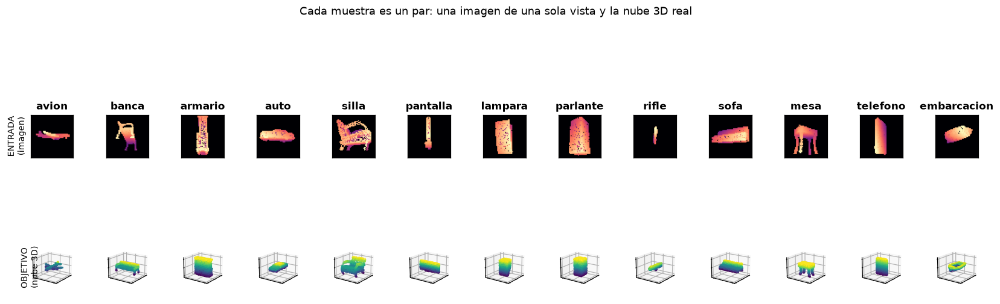

In [3]:
# =============================================================================
# 2.1 · EDA · PANORAMA DEL CONJUNTO
# =============================================================================
resumen = pd.DataFrame({
    "categoría": CATS,
    "muestras": [(Y_te == i).sum() for i in range(len(CATS))],
    "puntos por nube": CFG["n_puntos"],
    "píxeles ocupados (%)": [100 * (I_te[Y_te == i] > 0).mean() for i in range(len(CATS))],
    "extensión media": [np.ptp(P_te[Y_te == i], axis=1).mean() for i in range(len(CATS))],
}).round(2)
display(resumen)

fig = plt.figure(figsize=(15, 5.6))
for j, c in enumerate(CATS):
    k = int(np.where(Y_te == j)[0][0])
    a = fig.add_subplot(2, len(CATS), j + 1)
    a.imshow(I_te[k, 0], cmap="magma"); a.set_xticks([]); a.set_yticks([]); a.grid(False)
    a.set_title(c, fontsize=11, weight="bold")
    if j == 0: a.set_ylabel("ENTRADA\n(imagen)", fontsize=9)
    b = fig.add_subplot(2, len(CATS), len(CATS) + j + 1, projection="3d")
    p = P_te[k]; b.scatter(p[:, 0], p[:, 2], p[:, 1], s=1, c=p[:, 1], cmap="viridis")
    b.set_xlim(-.6, .6); b.set_ylim(-.6, .6); b.set_zlim(-.6, .6); b.view_init(18, 35)
    b.set_xticklabels([]); b.set_yticklabels([]); b.set_zticklabels([])
    if j == 0: b.text2D(-.25, .5, "OBJETIVO\n(nube 3D)", transform=b.transAxes, rotation=90, va="center", fontsize=9)
fig.suptitle("Cada muestra es un par: una imagen de una sola vista y la nube 3D real", fontsize=12, y=1.0)
plt.tight_layout(); guarda("eda1_panorama"); plt.show()

mx = resumen.loc[resumen["píxeles ocupados (%)"].idxmax(), "categoría"]
mn = resumen.loc[resumen["píxeles ocupados (%)"].idxmin(), "categoría"]
tarjeta("2.1 · Panorama del conjunto",
        "Arriba, la imagen que recibe el modelo; abajo, la nube 3D que debe producir. "
        "La tabla resume tamaño, ocupación de la imagen y extensión de cada categoría.",
        [f"{len(P_te)} pares de prueba, {len(CATS)} categorías equilibradas.",
         f"Cada nube: secuencia de {CFG['n_puntos']} vectores (x, y, z).",
         f"Mayor ocupación de imagen: <b>{mx}</b>; menor: <b>{mn}</b>."],
        ["La imagen pierde toda una dimensión: la profundidad solo se insinúa por el sombreado.",
         "El modelo debe <b>inventar la parte oculta</b> de forma plausible; por eso se necesita un modelo generativo."],
        "El dato de entrada es una imagen; el dato de salida es una secuencia de puntos sin orden.")

## 2.2 · EDA · Explorador interactivo

**Qué hace:** permite recorrer cualquier muestra del conjunto y verla desde varios ángulos: la imagen de entrada, la nube en 3D y sus tres proyecciones planas. Con `plotly` instalado se añade una vista 3D que se puede girar con el ratón.

**Uso:** mover el control *muestra* y cambiar el *ángulo*. Si `ipywidgets` no está disponible, se muestra una vista fija de la muestra 0.

interactive(children=(IntSlider(value=0, description='muestra', max=155), IntSlider(value=35, description='áng…

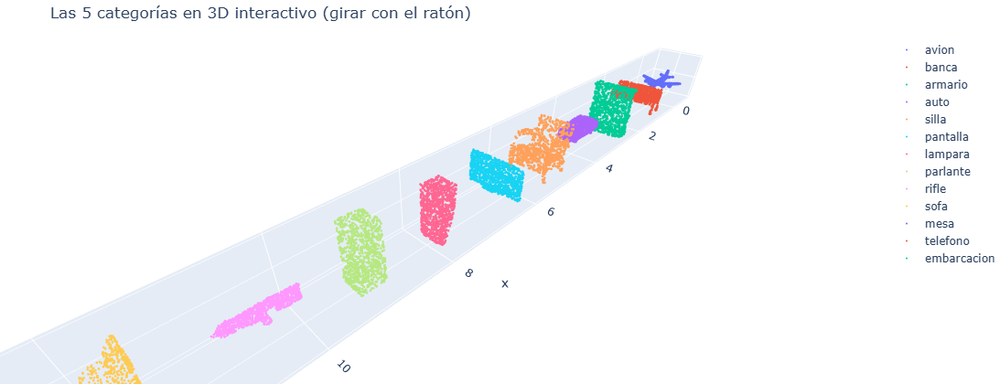

In [4]:
# =============================================================================
# 2.2 · EDA · EXPLORADOR INTERACTIVO
# =============================================================================
def vista_muestra(i=0, acimut=35):
    p = P_te[i]; c = CATS[int(Y_te[i])]
    fig = plt.figure(figsize=(15, 3.6))
    a = fig.add_subplot(1, 5, 1); a.imshow(I_te[i, 0], cmap="magma"); a.grid(False)
    a.set_xticks([]); a.set_yticks([]); a.set_title(f"entrada · {c} #{i}", fontsize=9)
    b = fig.add_subplot(1, 5, 2, projection="3d")
    b.scatter(p[:, 0], p[:, 2], p[:, 1], s=1.2, c=p[:, 1], cmap="viridis"); b.view_init(18, acimut)
    b.set_xlim(-.6, .6); b.set_ylim(-.6, .6); b.set_zlim(-.6, .6); b.set_title("nube 3D", fontsize=9)
    b.set_xticklabels([]); b.set_yticklabels([]); b.set_zticklabels([])
    for k, (u, v, nom) in enumerate([(0, 1, "frente (X-Y)"), (0, 2, "planta (X-Z)"), (2, 1, "perfil (Z-Y)")]):
        a = fig.add_subplot(1, 5, k + 3)
        a.hist2d(p[:, u], p[:, v], bins=40, range=[[-.6, .6], [-.6, .6]], cmap="Blues")
        a.set_title(nom, fontsize=9); a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([])
    plt.tight_layout(); plt.show()

try:
    import ipywidgets as W
    W.interact(vista_muestra, i=W.IntSlider(0, 0, len(P_te) - 1, description="muestra"),
               acimut=W.IntSlider(35, 0, 360, 15, description="ángulo"))
except ImportError:
    print("ipywidgets no disponible: vista fija (pip install ipywidgets para el explorador)")
    vista_muestra(0)

try:
    import plotly.graph_objects as go
    k = int(np.where(Y_te == CATS.index("silla"))[0][0]) if "silla" in CATS else 0
    fg = go.Figure()
    for j, c in enumerate(CATS):
        q = P_te[int(np.where(Y_te == j)[0][0])]
        fg.add_trace(go.Scatter3d(x=q[:, 0] + 1.3 * j, y=q[:, 2], z=q[:, 1], mode="markers",
                                  marker=dict(size=1.5), name=c))
    fg.update_layout(title="Las 5 categorías en 3D interactivo (girar con el ratón)", height=420,
                     scene=dict(aspectmode="data"), margin=dict(l=0, r=0, t=40, b=0))
    fg.show()
except ImportError:
    print("plotly no disponible: se omite la vista 3D rotable (pip install plotly)")

tarjeta("2.2 · Explorador interactivo",
        "Una misma muestra vista como imagen, como nube 3D y como tres proyecciones de densidad.",
        ["Las proyecciones revelan estructuras que la imagen oculta: patas traseras, respaldo, cola del avión.",
         "La vista de planta (X-Z) es la que menos información comparte con la imagen de entrada."],
        ["Lo que no aparece en la imagen es exactamente lo que el modelo tiene que deducir.",
         "Explorar varias muestras muestra la variabilidad dentro de cada categoría: no hay dos iguales."],
        "La imagen es una proyección; la nube recupera las tres dimensiones.")

## 2.3 · EDA · Geometría de las nubes

**Qué hace:** compara estadísticamente la forma de las categorías: cómo se reparten las coordenadas en cada eje y qué tamaño tiene la caja envolvente de cada objeto.

**Por qué importa:** si todas las categorías tuvieran la misma distribución, la imagen no aportaría nada y el modelo podría generar una forma promedio. Diferencias claras entre categorías significan que **la condición visual es necesaria**.

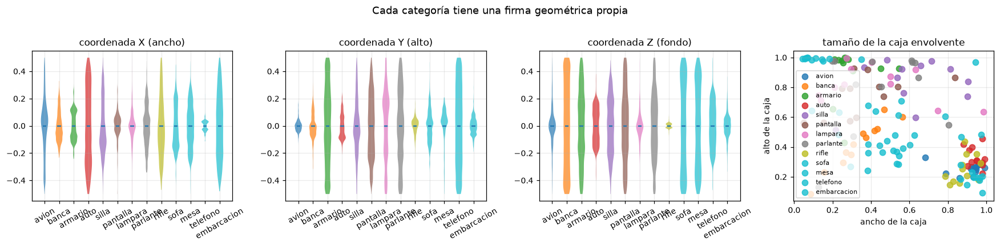

,σx,σy,σz
avion,0.209000,0.043000,0.154000
banca,0.112000,0.099000,0.304000
armario,0.107000,0.283000,0.263000
auto,0.272000,0.089000,0.130000
silla,0.200000,0.205000,0.205000
pantalla,0.103000,0.227000,0.260000
lampara,0.117000,0.255000,0.111000
parlante,0.156000,0.270000,0.242000
rifle,0.221000,0.059000,0.020000
sofa,0.162000,0.123000,0.311000


In [5]:
# =============================================================================
# 2.3 · EDA · GEOMETRÍA DE LAS NUBES
# =============================================================================
colores = plt.cm.tab10(np.arange(len(CATS)))
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
for e, nom in enumerate(["X (ancho)", "Y (alto)", "Z (fondo)"]):
    datos = [P_te[Y_te == i][:, :, e].ravel() for i in range(len(CATS))]
    vp = ax[e].violinplot(datos, showmeans=True, showextrema=False)
    for b_, col in zip(vp["bodies"], colores): b_.set_facecolor(col); b_.set_alpha(.7)
    ax[e].set_xticks(range(1, len(CATS) + 1)); ax[e].set_xticklabels(CATS, rotation=30)
    ax[e].set_title(f"coordenada {nom}")
ext = np.array([np.ptp(p, axis=0) for p in P_te])
for i, c in enumerate(CATS):
    ax[3].scatter(ext[Y_te == i, 0], ext[Y_te == i, 1], s=45, color=colores[i], label=c, alpha=.8)
ax[3].set_xlabel("ancho de la caja"); ax[3].set_ylabel("alto de la caja"); ax[3].legend(fontsize=7)
ax[3].set_title("tamaño de la caja envolvente")
fig.suptitle("Cada categoría tiene una firma geométrica propia", fontsize=12, y=1.02)
plt.tight_layout(); guarda("eda2_geometria"); plt.show()

std_eje = pd.DataFrame([P_te[Y_te == i].reshape(-1, 3).std(0) for i in range(len(CATS))],
                       index=CATS, columns=["σx", "σy", "σz"]).round(3)
display(std_eje.style.background_gradient(cmap="Blues", axis=None))
plano = std_eje["σy"].idxmin(); alto = std_eje["σy"].idxmax()
tarjeta("2.3 · Geometría de las nubes",
        "Distribución de cada coordenada por categoría (violines) y tamaño de la caja envolvente de cada objeto.",
        [f"Categoría más plana en altura: <b>{plano}</b> (σy = {std_eje.loc[plano,'σy']}).",
         f"Categoría con más desarrollo vertical: <b>{alto}</b> (σy = {std_eje.loc[alto,'σy']}).",
         "Las cajas envolventes forman grupos separados por categoría."],
        ["Las categorías ocupan regiones distintas del espacio de formas: <b>la tarea es aprendible</b>.",
         "Un modelo sin imagen solo podría acertar la forma promedio; la diferencia entre categorías obliga a usar la condición visual."],
        "Las formas son distintas entre sí; sin la imagen, el modelo no sabría cuál generar.")

## 2.4 · EDA · Separabilidad y ambigüedad de la vista única

**Qué hace:** dos análisis complementarios.

1. **Mapa de separabilidad:** cada objeto se resume con descriptores geométricos (extensiones y valores propios de su nube) y se proyecta en 2D con PCA. Si las categorías forman grupos, son distinguibles.
2. **Ambigüedad de la vista única:** para muchos pares de objetos se compara cuánto se parecen sus **imágenes** frente a cuánto se parecen sus **formas 3D**. Si imágenes parecidas pudieran venir de formas distintas, existe ambigüedad: es el corazón del problema.

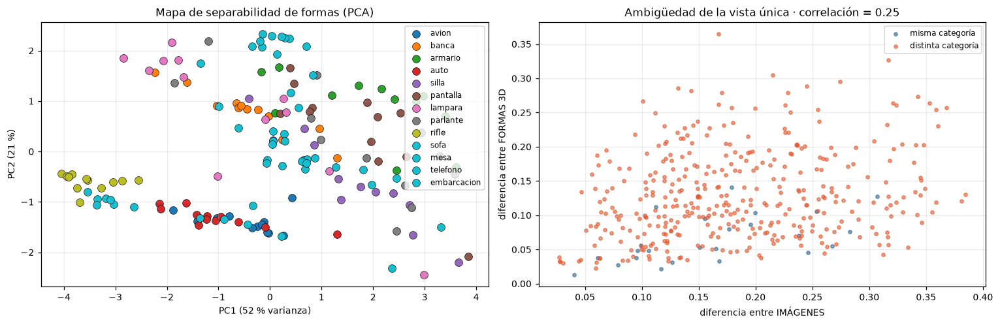

In [6]:
# =============================================================================
# 2.4 · EDA · SEPARABILIDAD Y AMBIGÜEDAD
# =============================================================================
def descriptores(p):
    ev = np.sort(np.linalg.eigvalsh(np.cov(p.T)))[::-1]
    return np.concatenate([np.ptp(p, 0), ev / ev.sum(), [np.linalg.norm(p, axis=1).mean()]])
Dsc = np.stack([descriptores(p) for p in P_te])
Dn = (Dsc - Dsc.mean(0)) / (Dsc.std(0) + 1e-9)
U, S, Vt = np.linalg.svd(Dn, full_matrices=False)
pcs = Dn @ Vt[:2].T; var = (S ** 2 / (S ** 2).sum())[:2]

rng_p = np.random.default_rng(0)
pares = rng_p.integers(0, len(P_te), size=(min(400, len(P_te) ** 2), 2))
pares = pares[pares[:, 0] != pares[:, 1]]
d_img = np.array([np.abs(I_te[a] - I_te[b]).mean() for a, b in pares])
Pt = torch.from_numpy(P_te)
d_3d = np.array([float(torch.cdist(Pt[a:a+1], Pt[b:b+1])[0].min(1).values.mean()) for a, b in pares])
misma = np.array([Y_te[a] == Y_te[b] for a, b in pares])
rho = float(np.corrcoef(d_img, d_3d)[0, 1])

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for i, c in enumerate(CATS):
    ax[0].scatter(pcs[Y_te == i, 0], pcs[Y_te == i, 1], s=60, color=colores[i], label=c, edgecolor="k", lw=.4)
ax[0].set_xlabel(f"PC1 ({100*var[0]:.0f} % varianza)"); ax[0].set_ylabel(f"PC2 ({100*var[1]:.0f} %)")
ax[0].legend(fontsize=8); ax[0].set_title("Mapa de separabilidad de formas (PCA)")
ax[1].scatter(d_img[misma], d_3d[misma], s=12, alpha=.6, label="misma categoría", color="#2f6690")
ax[1].scatter(d_img[~misma], d_3d[~misma], s=12, alpha=.6, label="distinta categoría", color="#e4572e")
ax[1].set_xlabel("diferencia entre IMÁGENES"); ax[1].set_ylabel("diferencia entre FORMAS 3D")
ax[1].legend(fontsize=8); ax[1].set_title(f"Ambigüedad de la vista única · correlación = {rho:.2f}")
plt.tight_layout(); guarda("eda3_separabilidad"); plt.show()

centros_pc = np.stack([pcs[Y_te == i].mean(0) for i in range(len(CATS))])
sep = float(np.mean([np.linalg.norm(centros_pc[i] - centros_pc[j])
                     for i in range(len(CATS)) for j in range(i + 1, len(CATS))]) /
            np.mean([pcs[Y_te == i].std() for i in range(len(CATS))]))
tarjeta("2.4 · Separabilidad y ambigüedad",
        "Izquierda: cada punto es un objeto resumido por su geometría. Derecha: cada punto es un par de objetos, "
        "comparando lo que se parecen sus imágenes con lo que se parecen sus formas.",
        [f"Las dos primeras componentes explican el {100*var.sum():.0f} % de la variabilidad geométrica.",
         f"Razón separación/dispersión entre categorías: <b>{sep:.1f}</b> (mayor que 1 = grupos distinguibles).",
         f"Correlación imagen–forma: <b>{rho:.2f}</b>."],
        ["Las categorías son separables por su geometría: el problema tiene solución.",
         ("La correlación es solo moderada: imágenes parecidas no garantizan formas parecidas. "
          "Esa es la <b>ambigüedad de la vista única</b> que justifica un modelo generativo."
          if rho < .8 else
          "La correlación es alta: en este banco la imagen determina bien la forma, lo que facilita la tarea "
          "frente a ShapeNet real.")],
        "Una misma silueta puede venir de varias formas; por eso se usa difusión y no una regresión directa.")

## 2.5 · EDA · La imagen como entrada y la densidad de puntos

**Qué hace:** caracteriza las dos entradas del modelo.

- **Imagen:** imagen media de cada categoría (la «silueta típica») e histograma de intensidades. Revela qué información visual está realmente disponible.
- **Nube:** distancia de cada punto a su vecino más cercano. Esa distancia fija la escala a la que trabajan las operaciones geométricas del modelo (radio de agrupamiento de la capa SA).

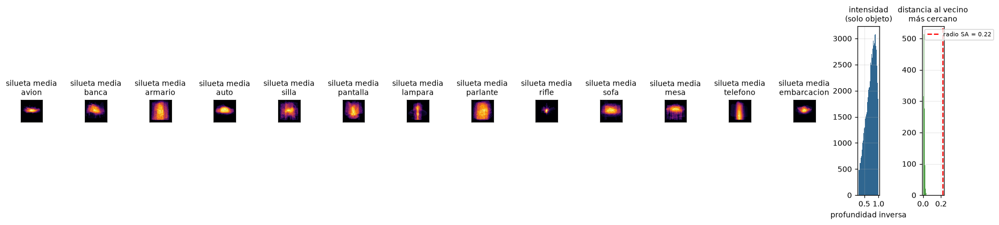

In [7]:
# =============================================================================
# 2.5 · EDA · IMAGEN DE ENTRADA Y DENSIDAD DE PUNTOS
# =============================================================================
fig = plt.figure(figsize=(16, 3.9))
for i, c in enumerate(CATS):
    a = fig.add_subplot(1, len(CATS) + 2, i + 1)
    a.imshow(I_te[Y_te == i, 0].mean(0), cmap="inferno"); a.grid(False); a.set_xticks([]); a.set_yticks([])
    a.set_title(f"silueta media\n{c}", fontsize=9)
a = fig.add_subplot(1, len(CATS) + 2, len(CATS) + 1)
v = I_te[I_te > 0]
a.hist(v, bins=40, color="#2f6690"); a.set_title("intensidad\n(solo objeto)", fontsize=9)
a.set_xlabel("profundidad inversa")
nn_d = torch.cdist(Pt[:10], Pt[:10]).topk(2, largest=False).values[..., 1].numpy().ravel()
a = fig.add_subplot(1, len(CATS) + 2, len(CATS) + 2)
a.hist(nn_d, bins=50, color="#54a24b"); a.axvline(CFG["radio"], color="red", ls="--", label=f"radio SA = {CFG['radio']}")
a.set_title("distancia al vecino\nmás cercano", fontsize=9); a.legend(fontsize=7)
plt.tight_layout(); guarda("eda4_entrada"); plt.show()

fondo = 100 * (I_te == 0).mean()
tarjeta("2.5 · Imagen de entrada y densidad",
        "Siluetas medias por categoría, reparto de intensidades del objeto y distancia típica entre puntos vecinos.",
        [f"El fondo ocupa el <b>{fondo:.0f} %</b> de los píxeles: la información está concentrada en pocos parches.",
         f"Distancia mediana al vecino: <b>{np.median(nn_d):.3f}</b>, muy inferior al radio de agrupamiento ({CFG['radio']}).",
         "Las siluetas medias son reconocibles: cada categoría tiene un patrón visual estable."],
        ["Que la mayoría de parches sean fondo explica por qué la atención del modelo puede repartirse "
         "de forma poco selectiva (sección 6).",
         f"Con el radio {CFG['radio']}, cada sub-nube reúne decenas de puntos: la capa SA trabaja con "
         "vecindarios ricos, a costa de solapamiento entre grupos."],
        "La imagen dice qué objeto es; la densidad de puntos dice a qué escala mirar la geometría.")

## 2.6 · EDA · ¿La imagen y la nube corresponden realmente?

**Qué hace:** comprueba, muestra a muestra, que la nube 3D es efectivamente el objeto que aparece en la imagen. Se proyecta la nube sobre el plano de la imagen y se mide el solapamiento (IoU) entre esa silueta y la del renderizado.

**Por qué importa:** es la verificación silenciosa que decide si el entrenamiento tiene sentido. Si la imagen y la nube no correspondieran, el modelo aprendería a ignorar la condición y la atención cruzada no tendría nada que aprender.

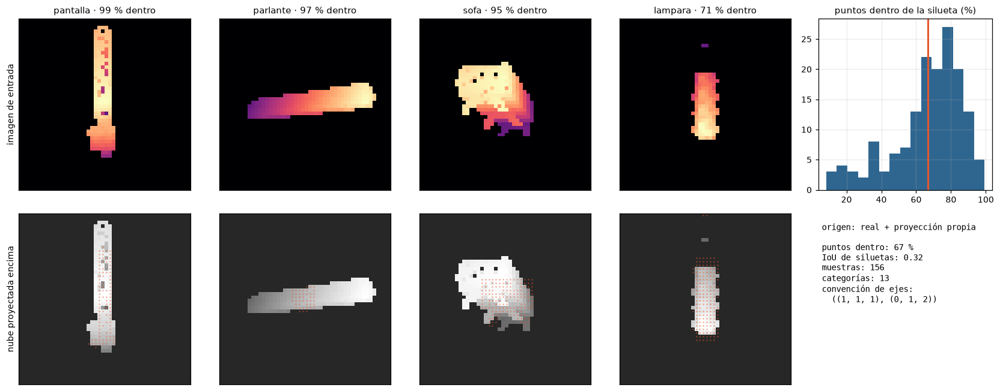

In [8]:
# =============================================================================
# 2.6 · EDA · CORRESPONDENCIA ENTRE LA IMAGEN Y LA NUBE
# =============================================================================
def silueta_de_nube(p, s):
    # silueta binaria de una nube proyectada ortogonalmente sobre el plano de la imagen
    ix = np.clip(((p[:, 0] + 0.5) * s).astype(int), 0, s - 1)
    iy = np.clip(((0.5 - p[:, 1]) * s).astype(int), 0, s - 1)
    m = np.zeros((s, s), bool); m[iy, ix] = True
    return m

S_IM = CFG["img_size"]
def coherencia(k):
    # fracción de puntos de la nube que caen dentro de la silueta de la imagen
    p = P_te[k]
    ix = np.clip(((p[:, 0] + 0.5) * S_IM).astype(int), 0, S_IM - 1)
    iy = np.clip(((0.5 - p[:, 1]) * S_IM).astype(int), 0, S_IM - 1)
    return float((I_te[k, 0] > 0.05)[iy, ix].mean())

ious = np.array([_iou(silueta_de_nube(P_te[k], S_IM), I_te[k, 0] > 0.05) for k in range(len(P_te))])
cohs = np.array([coherencia(k) for k in range(len(P_te))])
orden = np.argsort(-cohs)
sel = list(orden[:3]) + [int(orden[len(orden) // 2])]

fig, ax = plt.subplots(2, len(sel) + 1, figsize=(3.1 * (len(sel) + 1), 6))
for j, k in enumerate(sel):
    ax[0, j].imshow(I_te[k, 0], cmap="magma")
    ax[0, j].set_title(f"{CATS[Y_te[k]]} · {100*cohs[k]:.0f} % dentro", fontsize=10)
    ax[1, j].imshow(I_te[k, 0], cmap="gray", alpha=.85)
    yy, xx = np.where(silueta_de_nube(P_te[k], S_IM))
    ax[1, j].scatter(xx, yy, s=2.5, c="#e4572e", alpha=.55, lw=0)
    for a in (ax[0, j], ax[1, j]):
        a.set_xticks([]); a.set_yticks([]); a.grid(False)
ax[0, 0].set_ylabel("imagen de entrada", fontsize=9); ax[1, 0].set_ylabel("nube proyectada encima", fontsize=9)
ax[0, -1].hist(100 * cohs, bins=15, color="#2f6690")
ax[0, -1].set_title("puntos dentro de la silueta (%)", fontsize=10)
ax[0, -1].axvline(100 * cohs.mean(), color="#e4572e", lw=2)
ax[1, -1].axis("off")
ax[1, -1].text(.02, .95, f"origen: {INFO_DATOS['modo']}\n\npuntos dentro: {100*cohs.mean():.0f} %\n"
               f"IoU de siluetas: {ious.mean():.2f}\nmuestras: {len(cohs)}\ncategorías: {len(CATS)}"
               + (f"\nconvención de ejes:\n  {INFO_DATOS['conv']}" if INFO_DATOS.get("conv") else ""),
               va="top", fontsize=9, family="monospace", transform=ax[1, -1].transAxes)
plt.tight_layout(); guarda("eda6_alineacion"); plt.show()

tarjeta("2.6 · La imagen y la nube describen el mismo objeto",
        "Arriba, la vista que recibe el modelo; abajo, la misma vista con la nube 3D proyectada encima. "
        "El histograma resume el solapamiento en todo el conjunto de prueba.",
        [f"Puntos de la nube que caen dentro de la silueta de la imagen: <b>{100*cohs.mean():.0f} %</b> "
         f"(IoU de siluetas: {ious.mean():.2f}).",
         f"Origen de los datos: <b>{INFO_DATOS['modo']}</b>."
         + (f" Convención de ejes elegida automáticamente: {INFO_DATOS['conv']}." if INFO_DATOS.get("conv") else ""),
         "La proyección es ortográfica y la imagen es perspectiva: parte del desajuste es esperable."],
        ["Una coherencia alta confirma que el par (imagen, nube) es coherente: el modelo puede aprender "
         "la relación entre lo que se ve y la forma completa.",
         "Las muestras con menor coherencia suelen ser objetos alargados vistos de frente, donde la silueta ocupa "
         "pocos píxeles; son también las más difíciles de reconstruir.",
         "Esta comprobación sustituye a la confianza ciega en el formato del conjunto: cualquier error de "
         "ejes o de escala aparecería aquí de inmediato."],
        "Antes de entrenar o inferir se verifica que la imagen y la nube son el mismo objeto.")

# 3 · El modelo y sus pesos preentrenados

## Qué contiene esta celda

Todo el código del modelo, fiel a la Sección 3.4 del artículo, en un único bloque comentado:

| Pieza | Papel | Equivale en el artículo |
|---|---|---|
| `farthest_point_sample`, `ball_query` | eligen centros y vecindarios | «farthest point sampling» y sub-nubes de radio r |
| `CapaSA` | **encoder geométrico**: nube → tokens | *Set Abstraction layer* |
| `CodificadorImagen` | **encoder visual**: imagen → tokens | ViT |
| `timestep_embedding` | codifica el paso de ruido t | *timestep token* |
| `BloqueTransformer` | auto-atención + atención cruzada + FFN | Fig. 1, derecha |
| `CapaFP` | **decoder**: tokens → ruido por punto | *Feature Propagation layer* |
| `TrDPNet` | ensambla todo | Fig. 1, izquierda |
| `Difusion`, `muestrea` | proceso de ruido y muestreo | Ecuaciones 1-5, Algoritmo 2 |

## Pesos: carga, y adaptación al conjunto real si hace falta

El checkpoint guarda **los pesos, la configuración y el origen de los datos** con los que se obtuvieron. La celda sigue este orden:

1. Si ya existe un checkpoint entrenado sobre ShapeNet real (`weights/trdpnet_shapenet.pt`), se carga y se pasa directamente a la inferencia.
2. Si el checkpoint disponible procede del banco sintético, sus pesos se reutilizan como punto de partida y se **ajustan** al conjunto real durante unos pocos cientos de pasos. El resultado se guarda; las siguientes ejecuciones vuelven a ser de solo inferencia.
3. Si no hay ningún checkpoint, se prepara uno desde cero.

Ese ajuste es necesario porque un modelo de difusión aprende la *distribución* de las formas: los pesos obtenidos con formas sintéticas describen otra distribución distinta a la de ShapeNet.

> Los pesos oficiales del artículo (enlace en el repositorio original) corresponden a otra implementación (PyTorch3D, ViT de 768 dimensiones, 4 bloques de 768 canales) y no encajan en esta arquitectura reducida: cargarlos daría un error de dimensiones en cada capa. Se documentan como referencia en el informe.

Preparación de pesos: el checkpoint disponible se obtuvo con «origen desconocido»; se ajustan los existentes sobre «ShapeNet-R2N2 real».
[train] 2080 pares de 1040 modelos · modo: real + proyección propia


C:\Users\PersonalJR\anaconda3\envs\TrDPNet\Lib\site-packages\torch\nn\modules\transformer.py:382: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


  · pesos anteriores reutilizados como punto de partida
  [TrDPNet] paso     0/1200  loss=0.2155  lr=1.05e-04    19.7 s
  [TrDPNet] paso   120/1200  loss=0.2106  lr=9.45e-05    23.7 s
  [TrDPNet] paso   240/1200  loss=0.1996  lr=8.40e-05    27.2 s
  [TrDPNet] paso   360/1200  loss=0.1913  lr=7.35e-05    30.8 s
  [TrDPNet] paso   480/1200  loss=0.1916  lr=6.30e-05    34.4 s
  [TrDPNet] paso   600/1200  loss=0.2038  lr=5.25e-05    38.1 s
  [TrDPNet] paso   720/1200  loss=0.2101  lr=4.20e-05    41.8 s
  [TrDPNet] paso   840/1200  loss=0.1961  lr=3.15e-05    45.3 s
  [TrDPNet] paso   960/1200  loss=0.1966  lr=2.10e-05    48.9 s
  [TrDPNet] paso  1080/1200  loss=0.1789  lr=1.05e-05    52.4 s
  [TrDPNet] paso  1199/1200  loss=0.1838  lr=2.10e-06    55.8 s
Pesos cargados en 0.03 s · 1,590,915 parámetros · 6.44 MB · cuda


C:\Users\PersonalJR\anaconda3\envs\TrDPNet\Lib\site-packages\torch\nn\modules\transformer.py:382: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


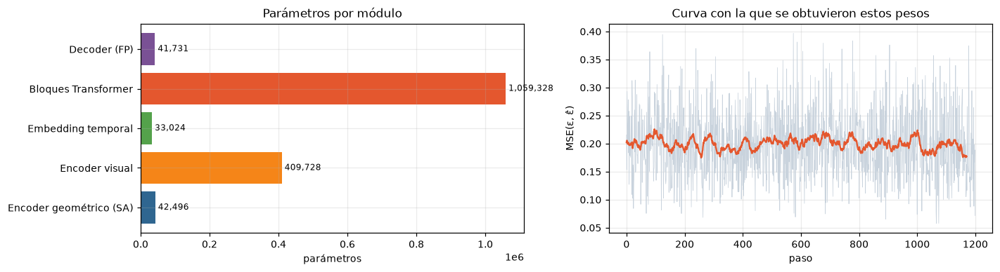

In [9]:
# =============================================================================
# 3 · MODELO TrDPNet + CARGA DE PESOS PREENTRENADOS
# =============================================================================
# ---- operaciones geométricas -------------------------------------------------
def farthest_point_sample(xyz, M):
    '''xyz (B,N,3) -> índices (B,M) de los puntos más separados entre sí.'''
    B, N, _ = xyz.shape
    idx = torch.zeros(B, M, dtype=torch.long, device=xyz.device)
    dist = torch.full((B, N), 1e10, device=xyz.device)
    lejano = torch.zeros(B, dtype=torch.long, device=xyz.device)
    ar = torch.arange(B, device=xyz.device)
    for i in range(M):
        idx[:, i] = lejano
        centro = xyz[ar, lejano].unsqueeze(1)
        d = ((xyz - centro) ** 2).sum(-1)
        dist = torch.minimum(dist, d)          # distancia al conjunto ya elegido
        lejano = dist.argmax(-1)               # el punto peor cubierto
    return idx

def index_points(x, idx):
    '''Indexado por lotes: x (B,N,C), idx (B,...) -> (B,...,C).'''
    B = x.shape[0]
    ar = torch.arange(B, device=x.device).view(B, *([1] * (idx.dim() - 1)))
    return x[ar, idx]

def ball_query(xyz, centros, radio, K):
    '''Para cada centro, K vecinos dentro de 'radio' (relleno con el más cercano).'''
    d = torch.cdist(centros, xyz)                       # (B,M,N)
    idx = d.argsort(-1)[:, :, :K]                       # K vecinos más próximos
    dk = torch.gather(d, 2, idx)
    primero = idx[:, :, :1].expand(-1, -1, K)
    return torch.where(dk <= radio, idx, primero), dk

# ---- encoders, bloque Transformer y decoder ----------------------------------
class CapaSA(nn.Module):
    '''Nube ruidosa (B,N,3) -> tokens (B,M,D) + centros (B,M,3).'''
    def __init__(self, M, K, radio, dim):
        super().__init__()
        self.M, self.K, self.radio = M, K, radio
        self.mlp = nn.Sequential(
            nn.Conv2d(3, 64, 1), nn.GroupNorm(8, 64), nn.GELU(),
            nn.Conv2d(64, 128, 1), nn.GroupNorm(8, 128), nn.GELU(),
            nn.Conv2d(128, dim, 1))
        self.pos = nn.Sequential(nn.Linear(3, dim), nn.GELU(), nn.Linear(dim, dim))

    def forward(self, xyz):
        fps = farthest_point_sample(xyz, self.M)
        kp = index_points(xyz, fps)                                   # (B,M,3) puntos clave
        idx, _ = ball_query(xyz, kp, self.radio, self.K)              # (B,M,K)
        rel = index_points(xyz, idx) - kp.unsqueeze(2)                # coords. relativas
        f = self.mlp(rel.permute(0, 3, 1, 2))                         # (B,D,M,K)
        z = f.max(dim=-1).values.transpose(1, 2)                      # max-pool -> (B,M,D)
        return z + self.pos(kp), kp, idx

class CodificadorImagen(nn.Module):
    '''Imagen (B,1,H,W) -> tokens visuales (B,I,D).'''
    def __init__(self, dim, img, patch, depth, heads, in_ch=1):
        super().__init__()
        self.proj = nn.Conv2d(in_ch, dim, kernel_size=patch, stride=patch)
        self.n_tokens = (img // patch) ** 2
        self.pos = nn.Parameter(torch.zeros(1, self.n_tokens, dim))
        nn.init.trunc_normal_(self.pos, std=0.02)
        capa = nn.TransformerEncoderLayer(dim, heads, dim * 4, batch_first=True,
                                          norm_first=True, activation="gelu", dropout=0.0)
        self.enc = nn.TransformerEncoder(capa, depth)
        self.norm = nn.LayerNorm(dim)

    def forward(self, img):
        x = self.proj(img).flatten(2).transpose(1, 2) + self.pos   # parches + posición
        return self.norm(self.enc(x))

def timestep_embedding(t, dim):
    '''t (B,) -> (B,dim) con pares coseno/seno de frecuencias geométricas.'''
    half = dim // 2
    freqs = torch.exp(-math.log(10000.0) * torch.arange(half, device=t.device) / half)
    ang = t.float()[:, None] * freqs[None]
    return torch.cat([torch.cos(ang), torch.sin(ang)], dim=-1)

class BloqueTransformer(nn.Module):
    def __init__(self, dim, heads, mlp_ratio=4.0, usar_self=True, modo_fusion="cross"):
        super().__init__()
        self.usar_self, self.modo_fusion = usar_self, modo_fusion
        self.n1 = nn.LayerNorm(dim)
        self.auto = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.n2 = nn.LayerNorm(dim); self.nc = nn.LayerNorm(dim)
        self.cruz = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.n3 = nn.LayerNorm(dim)
        self.ffn = nn.Sequential(nn.Linear(dim, int(dim * mlp_ratio)), nn.GELU(),
                                 nn.Linear(int(dim * mlp_ratio), dim))

    def forward(self, z, c, devolver_attn=False):
        M = z.shape[1]
        if self.modo_fusion == "concat":
            # Variante literal de la Ecuación (6): Splice(Attn(Cat(z,c)), M)
            h = self.n1(torch.cat([z, self.nc(c)], dim=1))
            o, w = self.auto(h, h, h, need_weights=devolver_attn, average_attn_weights=True)
            z = z + o[:, :M]
            z = z + self.ffn(self.n3(z))
            return z, (w[:, :M, M:] if w is not None else None)
        if self.usar_self:
            h = self.n1(z)
            z = z + self.auto(h, h, h, need_weights=False)[0]
        h, ck = self.n2(z), self.nc(c)
        o, w = self.cruz(h, ck, ck, need_weights=devolver_attn, average_attn_weights=True)
        z = z + o
        z = z + self.ffn(self.n3(z))
        return z, w

class CapaFP(nn.Module):
    '''(X_t, centros, z, ẑ) -> ruido predicho (B,N,3).'''
    def __init__(self, dim, k=3):
        super().__init__()
        self.k = k
        self.mlp = nn.Sequential(nn.Linear(2 * dim + 3, dim), nn.GELU(),
                                 nn.Linear(dim, dim // 2), nn.GELU(),
                                 nn.Linear(dim // 2, 3))

    def forward(self, xyz, centros, z, z_hat):
        d = torch.cdist(xyz, centros)                       # (B,N,M)
        dk, idx = d.topk(self.k, dim=-1, largest=False)     # 3 centros más cercanos
        w = 1.0 / (dk + 1e-8); w = w / w.sum(-1, keepdim=True)
        f  = (index_points(z,     idx) * w.unsqueeze(-1)).sum(2)
        fh = (index_points(z_hat, idx) * w.unsqueeze(-1)).sum(2)
        return self.mlp(torch.cat([xyz, f, fh], dim=-1)), w, idx

class TrDPNet(nn.Module):
    def __init__(self, cfg, usar_self=True, modo_fusion="cross"):
        super().__init__()
        d = cfg["dim"]
        self.sa  = CapaSA(cfg["M_centros"], cfg["K_vecinos"], cfg["radio"], d)
        self.img = CodificadorImagen(d, cfg["img_size"], cfg["patch"], cfg["img_depth"], cfg["heads"])
        self.t_mlp = nn.Sequential(nn.Linear(d, d), nn.SiLU(), nn.Linear(d, d))
        self.nulo = nn.Parameter(torch.zeros(1, self.img.n_tokens, d))   # token nulo (CFG)
        nn.init.trunc_normal_(self.nulo, std=0.02)
        self.bloques = nn.ModuleList([BloqueTransformer(d, cfg["heads"], 4.0, usar_self, modo_fusion)
                                      for _ in range(cfg["depth"])])
        self.fp = CapaFP(d)
        self.dim = d

    def forward(self, x_t, imagen, t, descartar=None, devolver_attn=False):
        z, centros, _ = self.sa(x_t)                       # encoder geométrico
        tokens_img = self.img(imagen)                      # encoder visual
        if descartar is not None:                          # guía sin clasificador
            m = descartar.view(-1, 1, 1).float()
            tokens_img = m * self.nulo.expand(tokens_img.shape[0], -1, -1) + (1 - m) * tokens_img
        t_tok = self.t_mlp(timestep_embedding(t, self.dim)).unsqueeze(1)
        c = torch.cat([tokens_img, t_tok], dim=1)          # condición (I+1) tokens
        z_hat, attn = z, None
        for blk in self.bloques:                           # cascada de L bloques
            z_hat, w = blk(z_hat, c, devolver_attn)
            if w is not None: attn = w
        eps, _, _ = self.fp(x_t, centros, z, z_hat)        # decoder geométrico
        return (eps, attn) if devolver_attn else (eps, None)

# ---- difusión, muestreo y métricas ----------------------------------------------
class Difusion:
    '''Calendario DDPM lineal con warmup, según la Sección 4.2 del artículo.'''
    def __init__(self, T, b0, b1, warmup, device):
        betas = torch.linspace(b0, b1, T)
        nw = max(1, int(T * warmup))
        betas[:nw] = torch.linspace(b0 * 0.1, b0, nw)     # arranque suave
        self.T = T
        self.betas = betas.to(device)
        self.alphas = 1.0 - self.betas
        self.ab = torch.cumprod(self.alphas, dim=0)       # alpha barra
        self.sqrt_ab = self.ab.sqrt()
        self.sqrt_1mab = (1 - self.ab).sqrt()

    def q_sample(self, x0, t, ruido):
        '''Ecuación (2): difusión directa en forma cerrada.
        Los coeficientes se mueven al dispositivo de x0, de modo que la misma
        instancia sirve para tensores en CPU (celdas de demostración) y en GPU
        (entrenamiento y muestreo) sin mezclar dispositivos.'''
        dev = x0.device
        a = self.ab.to(dev)[t.to(dev)].view(-1, 1, 1)
        return a.sqrt() * x0 + (1 - a).sqrt() * ruido

@torch.no_grad()
def muestrea(modelo, imagen, n_puntos, dif, omega=3.0, guardar=(), semilla=None, verbose=False):
    '''Algoritmo 2 del artículo. Devuelve (X_0, instantáneas).'''
    modelo.eval()
    if semilla is not None: torch.manual_seed(semilla)
    B = imagen.shape[0]
    x = torch.randn(B, n_puntos, 3, device=DEVICE)
    cond   = torch.zeros(B, dtype=torch.bool, device=DEVICE)
    uncond = torch.ones(B,  dtype=torch.bool, device=DEVICE)
    snaps = {}
    for i in reversed(range(dif.T)):
        t = torch.full((B,), i, device=DEVICE, dtype=torch.long)
        e_c, _ = modelo(x, imagen, t, descartar=cond)
        if omega != 1.0:
            e_u, _ = modelo(x, imagen, t, descartar=uncond)
            eps = e_u + omega * (e_c - e_u)          # Ecuación (5)
        else:
            eps = e_c
        a, ab = dif.alphas[i], dif.ab[i]
        x = (x - (1 - a) / (1 - ab).sqrt() * eps) / a.sqrt()     # Ecuación (4)
        if i > 0:
            x = x + dif.betas[i].sqrt() * torch.randn_like(x)
        if i in guardar: snaps[i] = x.clone().cpu().numpy()
        if verbose and i % max(1, dif.T // 5) == 0: print(f"    t={i}", flush=True)
    return x, snaps

def chamfer(pred, gt):
    '''CD simétrica por muestra. pred (B,N,3), gt (B,M,3) -> (B,)'''
    d = torch.cdist(pred, gt)
    return (d.min(2).values ** 2).mean(1) + (d.min(1).values ** 2).mean(1)

def f_score(pred, gt, tau):
    '''F-score@tau con precisión y recall. Devuelve (F, P, R), cada uno (B,).'''
    d = torch.cdist(pred, gt)
    p = (d.min(2).values < tau).float().mean(1)      # precisión
    r = (d.min(1).values < tau).float().mean(1)      # recall
    return 2 * p * r / (p + r + 1e-9), p, r

# ---- preparación de los pesos: carga, ajuste al conjunto real o entrenamiento ---
def entrena(modelo, X, IMG, dif, cfg, etiqueta="TrDPNet"):
    modelo.train()
    opt = torch.optim.AdamW(modelo.parameters(), lr=cfg["lr"], betas=(0.9, 0.999),
                            weight_decay=cfg["weight_decay"])
    hist = {"paso": [], "loss": [], "lr": [], "gnorm": [], "t": []}
    n = X.shape[0]; t0 = time.time()
    for paso in range(cfg["pasos"]):
        lr = cfg["lr"] * max(0.02, 1.0 - paso / cfg["pasos"])      # decaimiento lineal
        for g in opt.param_groups: g["lr"] = lr

        idx = torch.randint(0, n, (cfg["batch"],))
        x0 = X[idx].to(DEVICE); img = IMG[idx].to(DEVICE)
        t = torch.randint(0, dif.T, (cfg["batch"],), device=DEVICE)
        ruido = torch.randn_like(x0)
        x_t = dif.q_sample(x0, t, ruido)
        descartar = torch.rand(cfg["batch"], device=DEVICE) < cfg["p_uncond"]

        eps_hat, _ = modelo(x_t, img, t, descartar=descartar)
        loss = F.mse_loss(eps_hat, ruido)

        opt.zero_grad(set_to_none=True); loss.backward()
        gn = torch.nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
        opt.step()

        hist["paso"].append(paso); hist["loss"].append(loss.item())
        hist["lr"].append(lr); hist["gnorm"].append(float(gn)); hist["t"].append(t.float().mean().item())
        if paso % max(1, cfg["pasos"] // 10) == 0 or paso == cfg["pasos"] - 1:
            k = max(1, min(50, len(hist["loss"])))
            print(f"  [{etiqueta}] paso {paso:5d}/{cfg['pasos']}  loss={np.mean(hist['loss'][-k:]):.4f}"
                  f"  lr={lr:.2e}  {time.time()-t0:6.1f} s", flush=True)
    hist["segundos"] = time.time() - t0
    return hist

CLAVES_FORMA = ["n_puntos", "img_size", "patch", "dim", "depth", "heads", "img_depth", "M_centros", "K_vecinos"]
_ck0 = torch.load(RUTA_PESOS, map_location="cpu", weights_only=False) if RUTA_PESOS.exists() else None
_cfg0 = _ck0["cfg"] if _ck0 else None
_reutilizable = _ck0 is not None and all(_cfg0.get(k) == CFG.get(k) for k in CLAVES_FORMA)
_origen_ok = _ck0 is not None and _cfg0.get("datos") == CFG.get("datos")

if not (_ck0 is not None and _origen_ok):
    motivo = ("no hay ningún checkpoint" if _ck0 is None else
              f"el checkpoint disponible se obtuvo con «{_cfg0.get('datos', 'origen desconocido')}»")
    print(f"Preparación de pesos: {motivo}; se {'ajustan los existentes' if _reutilizable else 'entrenan nuevos'} "
          f"sobre «{CFG['datos']}».")
    P_tr, I_tr, Y_tr, META_tr = construye_conjunto_split("train", CFG["n_train_por_cat"], SEED + 1)
    CFG_ENT = dict(CFG)
    CFG_ENT["pasos"] = PASOS_AJUSTE if _reutilizable else PASOS_REAL
    if _reutilizable:
        CFG_ENT["lr"] = CFG["lr"] * 0.35          # ajuste fino: paso de aprendizaje menor
    torch.manual_seed(SEED)
    _m = TrDPNet(CFG).to(DEVICE)
    if _reutilizable:
        _m.load_state_dict(_ck0["state_dict"]); print("  · pesos anteriores reutilizados como punto de partida")
    _dif = Difusion(CFG["T"], CFG["beta_0"], CFG["beta_T"], CFG["warmup"], DEVICE)
    _h = entrena(_m, torch.from_numpy(P_tr), torch.from_numpy(I_tr), _dif, CFG_ENT)
    torch.save({"state_dict": {k: v.cpu() for k, v in _m.state_dict().items()}, "cfg": CFG,
                "historial": {k: _h[k] for k in ["paso", "loss", "lr", "gnorm"]},
                "meta": {"torch": torch.__version__, "device": str(DEVICE),
                         "fecha": time.strftime("%Y-%m-%d %H:%M"), "origen": CFG["datos"],
                         "partida": ("ajuste de " + RUTA_PESOS.name) if _reutilizable else "entrenamiento nuevo",
                         "pares_entrenamiento": len(P_tr),
                         "segundos_entrenamiento": round(_h["segundos"], 1)}}, SALIDA_PESOS)
    RUTA_PESOS = SALIDA_PESOS
    del _m
del _ck0

# ---- carga de los pesos (camino normal: solo inferencia) ---------------------
t0 = time.time()
ck = torch.load(RUTA_PESOS, map_location=DEVICE, weights_only=False)
modelo = TrDPNet(ck["cfg"]).to(DEVICE)
faltan = modelo.load_state_dict(ck["state_dict"], strict=True)
modelo.eval()
DIF = Difusion(CFG["T"], CFG["beta_0"], CFG["beta_T"], CFG["warmup"], DEVICE)
n_par = sum(p.numel() for p in modelo.parameters())
mb = RUTA_PESOS.stat().st_size / 1e6
print(f"Pesos cargados en {time.time()-t0:.2f} s · {n_par:,} parámetros · {mb:.2f} MB · {DEVICE}")

grupos = {"Encoder geométrico (SA)": modelo.sa, "Encoder visual": modelo.img,
          "Embedding temporal": modelo.t_mlp, "Bloques Transformer": modelo.bloques, "Decoder (FP)": modelo.fp}
conteo = {k: sum(p.numel() for p in v.parameters()) for k, v in grupos.items()}
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].barh(list(conteo), list(conteo.values()), color=["#2f6690", "#f58518", "#54a24b", "#e4572e", "#7a5195"])
for i, v in enumerate(conteo.values()): ax[0].text(v, i, f" {v:,}", va="center", fontsize=8)
ax[0].set_title("Parámetros por módulo"); ax[0].set_xlabel("parámetros")
h = ck.get("historial", {})
if h.get("loss"):
    L = np.array(h["loss"]); k = max(1, len(L) // 40)
    ax[1].plot(L, color="#c9d3dd", lw=.5); ax[1].plot(np.convolve(L, np.ones(k) / k, "valid"), color="#e4572e")
    ax[1].set_title("Curva con la que se obtuvieron estos pesos"); ax[1].set_xlabel("paso"); ax[1].set_ylabel("MSE(ε, ε̂)")
plt.tight_layout(); guarda("modelo_parametros"); plt.show()

dom = max(conteo, key=conteo.get)
tarjeta("3 · Modelo cargado desde los pesos preentrenados",
        "Reparto de parámetros entre los módulos del modelo y la curva de pérdida registrada dentro del checkpoint.",
        [f"<b>{n_par:,}</b> parámetros en {mb:.2f} MB; carga estricta: todas las claves coinciden.",
         f"Origen de los datos con los que se obtuvieron: <b>{ck['cfg'].get('datos', 'no registrado')}</b>"
         + (f" · {ck['meta'].get('partida', '')}" if ck.get("meta") else "") + ".",
         f"Módulo con más parámetros: <b>{dom}</b> ({100*conteo[dom]/n_par:.0f} %).",
         (f"La pérdida registrada baja de {np.mean(h['loss'][:20]):.3f} a {np.mean(h['loss'][-20:]):.3f}."
          if h.get("loss") else "El checkpoint no incluye historial de pérdida.")],
        ["La fusión multimodal (bloques Transformer) concentra la capacidad del modelo: es donde ocurre la innovación.",
         "Una MSE inferior a 1 significa que el modelo predice el ruido mejor que el azar: los pesos contienen conocimiento útil."],
        "El proyecto usa los pesos para inferir; no hace falta entrenar durante la demostración.")

# 4 · Entradas y salidas del modelo

## La pregunta que más se confunde

| | Qué es | Forma |
|---|---|---|
| **Entrada 1 · imagen v** | la vista única del objeto | (1, H, W) |
| **Entrada 2 · nube ruidosa X_t** | un estado intermedio entre ruido y objeto | (N, 3) |
| **Entrada 3 · paso t** | cuánto ruido queda (0 = limpio, T = ruido puro) | escalar |
| **Salida · ε̂** | **el ruido estimado** que contamina a X_t | (N, 3) |

**La salida no son coordenadas.** El modelo responde a la pregunta «¿qué parte de esta nube es ruido?». Restando ese ruido poco a poco, T veces, aparece el objeto:

$$x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon \qquad\text{(proceso directo: añadir ruido)}$$

$$x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\Big(x_t - \frac{1-\alpha_t}{\sqrt{1-\bar\alpha_t}}\,\hat\epsilon\Big) + \sigma_t z \qquad\text{(proceso inverso: quitar ruido)}$$

La animación muestra el proceso directo; el modelo aprende a recorrerlo al revés.

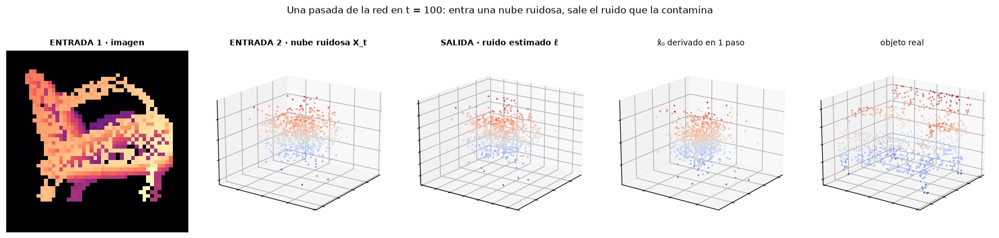

In [10]:
# =============================================================================
# 4 · ENTRADAS Y SALIDAS (con animación del proceso directo)
# =============================================================================
i_demo = int(np.where(Y_te == CATS.index("silla"))[0][0]) if "silla" in CATS else 0
x0 = X_te[i_demo:i_demo + 1].to(DEVICE); img0 = IMG_te[i_demo:i_demo + 1].to(DEVICE)

# --- una pasada real del modelo: entradas y salida ----------------------------
t_io = torch.tensor([int(DIF.T * .5)], device=DEVICE)
ruido = torch.randn_like(x0)
with torch.no_grad():
    xt = DIF.q_sample(x0, t_io, ruido)
    eps, _ = modelo(xt, img0, t_io, descartar=torch.zeros(1, dtype=torch.bool, device=DEVICE))
ab = DIF.ab[t_io].view(-1, 1, 1)
x0_est = (xt - (1 - ab).sqrt() * eps) / ab.sqrt()          # estimación de un solo paso
err_eps = F.mse_loss(eps, ruido).item()

fig = plt.figure(figsize=(16, 3.8))
paneles = [("ENTRADA 1 · imagen", None), ("ENTRADA 2 · nube ruidosa X_t", xt[0]),
           ("SALIDA · ruido estimado ε̂", eps[0]), ("x̂₀ derivado en 1 paso", x0_est[0]), ("objeto real", x0[0])]
for k, (tit, dat) in enumerate(paneles):
    if dat is None:
        a = fig.add_subplot(1, 5, 1); a.imshow(img0[0, 0].cpu(), cmap="magma"); a.grid(False)
        a.set_xticks([]); a.set_yticks([])
    else:
        a = fig.add_subplot(1, 5, k + 1, projection="3d"); q = dat.cpu().numpy()
        a.scatter(q[:, 0], q[:, 2], q[:, 1], s=1, c=q[:, 1], cmap="coolwarm"); a.view_init(18, 35)
        a.set_xticklabels([]); a.set_yticklabels([]); a.set_zticklabels([])
    a.set_title(tit, fontsize=9, weight="bold" if "SALIDA" in tit or "ENTRADA" in tit else None)
fig.suptitle(f"Una pasada de la red en t = {t_io.item()}: entra una nube ruidosa, sale el ruido que la contamina", y=1.03)
plt.tight_layout(); guarda("entradas_salidas"); plt.show()

# --- animación: proceso directo ---------------------------------------------------
ab_np = DIF.ab.cpu().numpy(); pasos_a = np.linspace(0, DIF.T - 1, N_FRAMES).astype(int)
fig_f = plt.figure(figsize=(9.5, 3.9)); a3 = fig_f.add_subplot(1, 2, 1, projection="3d"); a2 = fig_f.add_subplot(1, 2, 2)
col = x0[0, :, 1].cpu().numpy()
def _f(i):
    t_ = int(pasos_a[i]); q = DIF.q_sample(x0, torch.tensor([t_], device=DEVICE), ruido)[0].cpu().numpy()
    a3.clear(); a3.scatter(q[:, 0], q[:, 2], q[:, 1], s=1.3, c=col, cmap="viridis")
    lim = .8 + 1.6 * (1 - np.sqrt(ab_np[t_])); a3.set_xlim(-lim, lim); a3.set_ylim(-lim, lim); a3.set_zlim(-lim, lim)
    a3.set_xticklabels([]); a3.set_yticklabels([]); a3.set_zticklabels([]); a3.set_title(f"t = {t_}")
    a2.clear(); a2.plot(np.sqrt(ab_np), label="señal"); a2.plot(np.sqrt(1 - ab_np), label="ruido")
    a2.axvline(t_, color="k"); a2.legend(fontsize=8); a2.set_xlabel("t"); a2.set_title("mezcla señal/ruido")
anima(fig_f, _f, N_FRAMES, "01_proceso_directo")

tarjeta("4 · Entradas y salidas",
        "Una pasada real: la red recibe la imagen, una nube ruidosa y el paso t, y devuelve el ruido estimado. "
        "La animación muestra cómo el objeto se disuelve en ruido al avanzar t.",
        [f"Error de la predicción de ruido en t = {t_io.item()}: MSE = <b>{err_eps:.3f}</b> (1.0 sería adivinar al azar).",
         "La salida ε̂ tiene la misma forma que la entrada X_t: (N, 3).",
         "El x̂₀ de un solo paso es tosco: la calidad sale de iterar, no de una pasada."],
        ["El modelo no dibuja el objeto de una vez: corrige una nube ruidosa, y lo hace T veces.",
         "La animación es el camino que el modelo aprendió a recorrer al revés."],
        "La red predice ruido, no coordenadas; las coordenadas emergen al restar ese ruido paso a paso.")

# 5 · La arquitectura encoder–decoder, pieza a pieza

## Recorrido de los datos

1. **Encoder geométrico (capa SA).** El *farthest point sampling* elige M centros bien repartidos; alrededor de cada uno se toma una sub-nube de radio r; un MLP y un *max-pooling* la resumen en **un token**. Resultado: N puntos → M tokens.
2. **Encoder visual.** La imagen se trocea en parches; cada parche es un token. Se añade **un token más** con el paso t. Esta es la **condición c**.
3. **Bloques Transformer (×L).** Cada bloque hace tres cosas: los tokens de la nube hablan entre sí (**auto-atención**), consultan la imagen (**atención cruzada**) y se transforman (*feed-forward*).
4. **Decoder (capa FP).** Los M tokens se reparten de vuelta a los N puntos por interpolación con los 3 centros más cercanos, y un MLP predice el ruido de cada punto.

**¿Por qué encoder–decoder?** El encoder comprime (N puntos → M tokens), el Transformer razona en ese espacio compacto combinando geometría e imagen, y el decoder devuelve la respuesta a la resolución original. La atención cruzada es el puente entre las dos modalidades.

## 5.1 · La Figura 1 del artículo, reproducida con datos de este proyecto

**Qué hace:** redibuja la figura que resume toda la arquitectura, pero con **nubes reales de esta ejecución** en el panel superior: el ruido puro, un estado intermedio y el objeto limpio, obtenidos con el proceso directo de difusión sobre una muestra del conjunto.

**Cómo leerla:**

| Panel | Qué muestra | Dónde está en el código |
|---|---|---|
| Arriba | el proceso de eliminación de ruido: de $x_T$ a $x_0$ | `muestrea` (sección 8) |
| Abajo | la estructura: capa SA → bloques Transformer → capa FP | `TrDPNet.forward` |
| Derecha | el interior de un bloque, con la atención cruzada añadida | `BloqueTransformer.forward` |

El detalle clave está en el panel derecho: además de la auto-atención y del avance directo del Transformer clásico, aparece un **tercer subbloque de atención cruzada** alimentado por la condición (imagen + paso temporal). Esa es la modificación que propone el artículo.

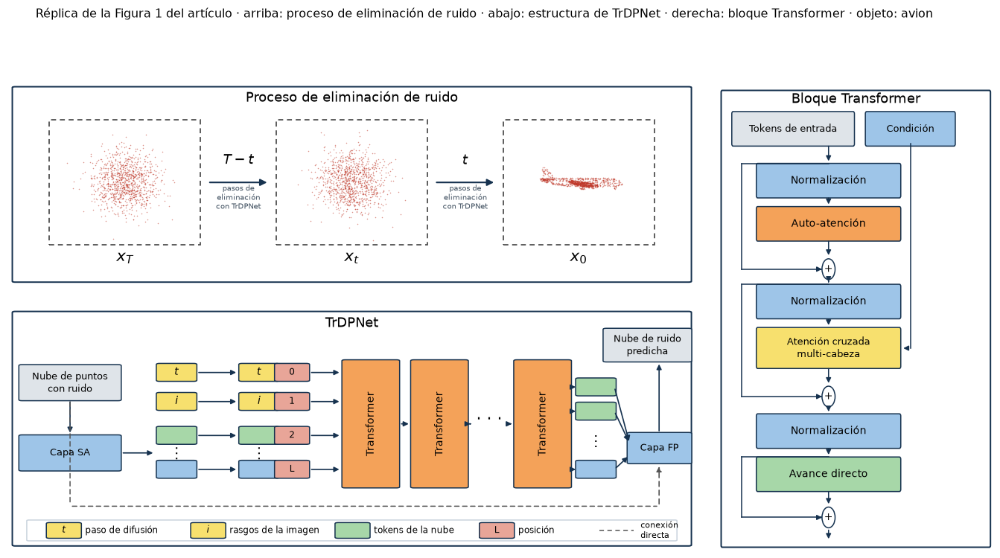

In [11]:
# =============================================================================
# 5.1 · RÉPLICA DE LA FIGURA 1 DEL ARTÍCULO CON NUBES PROPIAS
# =============================================================================
def figura_uno(x0, xt, xT, titulo_extra=""):
    '''Reproduce la Figura 1 del artículo usando nubes reales de este proyecto.

    x0: objeto limpio · xt: estado intermedio · xT: ruido puro (cada uno (N,3)).'''
    AZ, NA, VE, AM, GR, RO = "#9ec5e8", "#f4a259", "#a7d7a8", "#f7e06e", "#dfe4e9", "#e8a598"
    T3 = "#16324f"
    fig = plt.figure(figsize=(15.5, 7.4))
    gs = fig.add_gridspec(2, 2, width_ratios=[2.9, 1.15], height_ratios=[1, 1.2], wspace=0.05, hspace=0.1)

    # =================== panel superior izquierdo ============================
    ax = fig.add_subplot(gs[0, 0]); ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.axis("off")
    ax.add_patch(FancyBboxPatch((1, 2), 98, 96, boxstyle="round,pad=0.4", fc="white", ec=T3, lw=1.3))
    ax.text(50, 91, "Proceso de eliminación de ruido", ha="center", fontsize=12)
    for p, cx, etq in [(xT, 17, "$x_T$"), (xt, 50, "$x_t$"), (x0, 83, "$x_0$")]:
        ax.add_patch(Rectangle((cx - 11, 20), 22, 62, fill=False, ec="#444", ls=(0, (4, 3)), lw=1.1))
        sub = ax.inset_axes([(cx - 10.5) / 100, 0.21, 0.21, 0.60])
        sub.scatter(p[:, 0], p[:, 1], s=1.0, c="#c0392b", alpha=.55, lw=0)
        lim = max(0.7, float(np.abs(p[:, :2]).max()) * 1.05)
        sub.set_xlim(-lim, lim); sub.set_ylim(-lim, lim)
        sub.set_aspect("equal"); sub.axis("off"); sub.patch.set_alpha(0)
        ax.text(cx, 12, etq, ha="center", fontsize=14)
    for x1, x2, arriba in [(29, 38, "$T-t$"), (62, 71, "$t$")]:
        ax.add_patch(FancyArrowPatch((x1, 51), (x2, 51), arrowstyle="-|>", mutation_scale=12, lw=1.4, color=T3))
        ax.text((x1 + x2) / 2, 60, arriba, ha="center", fontsize=12)
        ax.text((x1 + x2) / 2, 38, "pasos de\neliminación\ncon TrDPNet",
                ha="center", fontsize=6.5, color="#405060")

    # =================== panel inferior izquierdo ============================
    ax = fig.add_subplot(gs[1, 0]); ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.axis("off")
    ax.add_patch(FancyBboxPatch((1, 2), 98, 96, boxstyle="round,pad=0.4", fc="white", ec=T3, lw=1.3))
    ax.text(50, 92, "TrDPNet", ha="center", fontsize=12)

    def caja(x, y, w, h, txt, fc, fs=8.5):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.45", fc=fc, ec=T3, lw=1.0))
        ax.text(x + w / 2, y + h / 2, txt, ha="center", va="center", fontsize=fs)

    def fle(p, q, ls="-", c=T3, lw=1.1):
        ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=9, lw=lw, color=c, ls=ls))

    caja(2, 62, 14, 14, "Nube de puntos\ncon ruido", GR)
    caja(2, 33, 14, 14, "Capa SA", AZ)
    fle((9, 62), (9, 47.4))
    fle((16.4, 40), (21.4, 40))
    filas = [(70, "$t$", AM, "0"), (58, "$i$", AM, "1"), (44, "", VE, "2"), (30, "", AZ, "L")]
    for y, tx, col, pos in filas:
        caja(22, y, 5, 6.5, tx, col, fs=9)
        fle((27.4, y + 3.2), (33.5, y + 3.2))
        caja(34, y, 5, 6.5, tx, col, fs=9)
        caja(39.2, y, 4.2, 6.5, pos, RO, fs=8)
        fle((43.8, y + 3.2), (48.5, y + 3.2))
    ax.text(24.5, 38, "⋮", ha="center", fontsize=13)
    ax.text(36.5, 38, "⋮", ha="center", fontsize=13)
    for x in (49, 59, 74):
        ax.add_patch(FancyBboxPatch((x, 26), 7.5, 52, boxstyle="round,pad=0.45", fc=NA, ec=T3, lw=1.0))
        ax.text(x + 3.75, 52, "Transformer", ha="center", va="center", fontsize=9, rotation=90)
    ax.text(70, 52, "· · ·", ha="center", fontsize=14)
    fle((56.9, 52), (58.6, 52)); fle((66.9, 52), (67.6, 52)); fle((72.6, 52), (73.6, 52))
    for y, col in [(64, VE), (54, VE), (30, AZ)]:
        caja(83, y, 5, 6.5, "", col)
        fle((81.6, y + 3.2), (82.9, y + 3.2))
    ax.text(85.5, 43, "⋮", ha="center", fontsize=13)
    caja(90.5, 36, 8.5, 12, "Capa FP", AZ)
    caja(87, 78, 12, 13, "Nube de ruido\npredicha", GR)
    for y in (64, 54, 30):
        fle((88.2, y + 3.2), (90.4, 44 if y > 40 else 39))
    fle((94.7, 48.2), (94.7, 77.6))
    ax.add_patch(FancyArrowPatch((9, 62), (9, 18), arrowstyle="-", ls=(0, (4, 3)), lw=1, color="#555"))
    ax.add_patch(FancyArrowPatch((9, 18), (94.7, 18), arrowstyle="-", ls=(0, (4, 3)), lw=1, color="#555"))
    fle((94.7, 18), (94.7, 35.4), ls=(0, (4, 3)), c="#555")
    ax.add_patch(FancyBboxPatch((3, 4), 94, 8, boxstyle="round,pad=0.3", fc="white", ec="#c9d3dd"))
    x = 6
    for tx, col, txt in [("$t$", AM, "paso de difusión"), ("$i$", AM, "rasgos de la imagen"),
                         ("", VE, "tokens de la nube"), ("L", RO, "posición")]:
        caja(x, 5.2, 4.2, 5.6, tx, col, fs=8)
        ax.text(x + 5.2, 8, txt, va="center", fontsize=8)
        x += 21
    ax.plot([86, 91], [8, 8], ls=(0, (4, 3)), color="#555", lw=1)
    ax.text(92, 8, "conexión\ndirecta", va="center", fontsize=7)

    # =================== panel derecho: bloque Transformer ===================
    ax = fig.add_subplot(gs[:, 1]); ax.set_xlim(0, 100); ax.set_ylim(-8, 100); ax.axis("off")
    ax.add_patch(FancyBboxPatch((1, -7), 98, 105, boxstyle="round,pad=0.4", fc="white", ec=T3, lw=1.3))
    ax.text(50, 95.5, "Bloque Transformer", ha="center", fontsize=11.5)

    def cajab(y, txt, fc, x=14, w=52, h=7, fs=9):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.5", fc=fc, ec=T3, lw=1.0))
        ax.text(x + w / 2, y + h / 2, txt, ha="center", va="center", fontsize=fs)

    def suma(y):
        ax.add_patch(Circle((40, y), 2.4, fc="white", ec=T3, lw=1.0))
        ax.text(40, y, "+", ha="center", va="center", fontsize=9)

    def fle2(p, q, c=T3, ls="-"):
        ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=9, lw=1.0, color=c, ls=ls))

    cajab(86, "Tokens de entrada", GR, x=5, w=44, h=7, fs=8.5)
    cajab(86, "Condición", AZ, x=54, w=32, h=7, fs=8.5)
    cajab(74, "Normalización", AZ)
    cajab(64, "Auto-atención", NA)
    suma(57)
    cajab(46, "Normalización", AZ)
    cajab(34.5, "Atención cruzada\nmulti-cabeza", AM, h=8.5, fs=8.5)
    suma(27.5)
    cajab(16, "Normalización", AZ)
    cajab(6, "Avance directo", VE)
    suma(-0.5)
    for ya, yb in [(86, 81.5), (74, 71.5), (64, 59.7), (54.6, 53.5), (46, 43.5), (34.5, 30.1), (25.1, 23.5),
                   (16, 13.5), (6, 2.1)]:
        fle2((40, ya), (40, yb))
    for ya, yb in [(81.5, 57), (53.5, 27.5), (13.5, -0.5)]:      # conexiones residuales
        ax.plot([8, 8], [ya, yb], color=T3, lw=1.0)
        ax.plot([8, 37.4], [yb, yb], color=T3, lw=1.0)
        ax.plot([8, 40], [ya, ya], color=T3, lw=1.0)
        fle2((36, yb), (37.6, yb))
    ax.plot([70, 70], [86, 38.7], color=T3, lw=1.0)              # la condición entra en la atención cruzada
    fle2((70, 38.7), (66.6, 38.7))
    fle2((40, -2.9), (40, -6))

    fig.suptitle("Réplica de la Figura 1 del artículo · arriba: proceso de eliminación de ruido · abajo: estructura "
                 f"de TrDPNet · derecha: bloque Transformer{titulo_extra}", fontsize=10.5, y=1.005)
    return fig

_k = int(np.where(Y_te == CATS.index("avion"))[0][0]) if "avion" in CATS else 0
_x0 = X_te[_k:_k + 1].to(DEVICE)
torch.manual_seed(11)
_xt = DIF.q_sample(_x0, torch.tensor([int(DIF.T * 0.45)], device=DEVICE), torch.randn_like(_x0))
_xT = torch.randn_like(_x0) * 0.5
fig = figura_uno(_x0[0].cpu().numpy(), _xt[0].detach().cpu().numpy(), _xT[0].cpu().numpy(),
                 titulo_extra=f" · objeto: {CATS[Y_te[_k]]}")
guarda("fig1_articulo"); plt.show()

tarjeta("5.1 · La arquitectura completa en una sola imagen",
        "Réplica de la Figura 1 del artículo. Las tres nubes del panel superior no son un dibujo: son la misma "
        f"muestra de la categoría <b>{CATS[Y_te[_k]]}</b> en tres niveles de ruido, calculados con la ecuación del proceso directo.",
        [f"Izquierda arriba: {CFG['n_puntos']} puntos pasan de ruido gaussiano al objeto en {DIF.T} pasos.",
         f"Izquierda abajo: la capa SA comprime la nube a {CFG['M_centros']} tokens, {CFG['depth']} bloques "
         "Transformer los procesan y la capa FP devuelve un vector de ruido por punto.",
         "Derecha: cada bloque es Normalización → Auto-atención → Normalización → <b>Atención cruzada</b> → "
         "Normalización → Avance directo, con conexión residual en los tres."],
        ["El modelo nunca ve la nube completa en el Transformer: trabaja sobre un resumen de tokens, que es lo "
         "que hace viable la atención sobre miles de puntos.",
         "La condición (imagen + paso t) entra <b>solo</b> por la atención cruzada; todo lo demás es el "
         "Transformer estándar de Vaswani.",
         "La conexión directa punteada lleva la nube original hasta la capa FP: sin ella, el decoder no sabría "
         "a qué coordenadas corresponde cada token."],
        "Esta figura es el mapa del proyecto: conviene tenerla a la vista durante toda la exposición.")

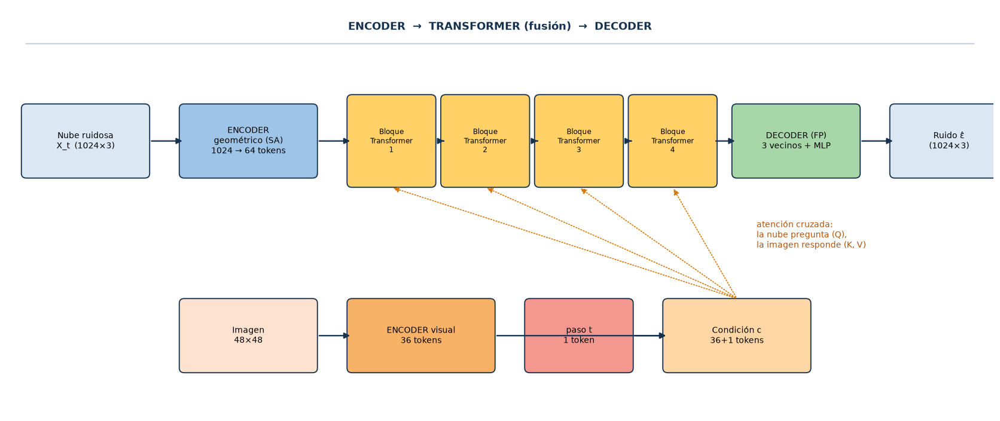

,etapa,forma del tensor,elementos
0,nube ruidosa X_t (entrada),"(1, 1024, 3)",3072
1,imagen (entrada),"(1, 1, 48, 48)",2304
2,tokens de la nube z,"(1, 64, 128)",8192
3,tokens de la imagen,"(1, 36, 128)",4608
4,token del paso t,"(1, 128)",128
5,salida bloque 1,"(1, 64, 128)",8192
6,salida bloque 2,"(1, 64, 128)",8192
7,salida bloque 3,"(1, 64, 128)",8192
8,salida bloque 4,"(1, 64, 128)",8192
9,ruido predicho ε̂,"(1, 1024, 3)",3072


In [12]:
# =============================================================================
# 5 · DIAGRAMA DE LA ARQUITECTURA + VIAJE DE UN TENSOR
# =============================================================================
fig = plt.figure(figsize=(15, 6.2)); ax = fig.add_axes([0, 0, 1, 1]); ax.axis("off")
ax.set_xlim(0, 100); ax.set_ylim(0, 44)
Dd, Mm, Ii = CFG["dim"], CFG["M_centros"], (CFG["img_size"] // CFG["patch"]) ** 2
def bx(x, y, w, h, t, fc, fs=9):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=.5", fc=fc, ec="#16324f", lw=1.2))
    ax.text(x + w / 2, y + h / 2, t, ha="center", va="center", fontsize=fs)
def ar(p, q, c="#16324f", lw=1.5, ls="-"):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=13, color=c, lw=lw, linestyle=ls))
bx(2, 26, 12, 7, f"Nube ruidosa\nX_t  ({CFG['n_puntos']}×3)", "#dbe7f3")
bx(18, 26, 13, 7, f"ENCODER\ngeométrico (SA)\n{CFG['n_puntos']} → {Mm} tokens", "#9ec5e8")
for k in range(CFG["depth"]):
    bx(35 + k * 9.5, 25, 8, 9, f"Bloque\nTransformer\n{k+1}", "#ffd166", 8)
    if k: ar((34.6 + k * 9.5, 29.5), (35 + k * 9.5, 29.5))
ar((14.5, 29.5), (18, 29.5)); ar((31.5, 29.5), (35, 29.5))
xf = 35 + CFG["depth"] * 9.5
bx(xf + 1, 26, 12, 7, "DECODER (FP)\n3 vecinos + MLP", "#a7d7a8")
bx(xf + 17, 26, 11, 7, f"Ruido ε̂\n({CFG['n_puntos']}×3)", "#dbe7f3")
ar((xf - 1.3, 29.5), (xf + 1, 29.5)); ar((xf + 13.5, 29.5), (xf + 17, 29.5))
bx(18, 5, 13, 7, f"Imagen\n{CFG['img_size']}×{CFG['img_size']}", "#fde2cf")
bx(35, 5, 14, 7, f"ENCODER visual\n{Ii} tokens", "#f7b267")
bx(53, 5, 10, 7, "paso t\n1 token", "#f4978e")
bx(67, 5, 14, 7, f"Condición c\n{Ii}+1 tokens", "#ffd6a5")
ar((31.5, 8.5), (35, 8.5)); ar((49.5, 8.5), (67, 8.5)); ar((63.5, 8.5), (67, 8.5))
for k in range(CFG["depth"]):
    ar((74, 12.5), (39 + k * 9.5, 24.5), c="#d97706", lw=1.1, ls=":")
ax.text(76, 18, "atención cruzada:\nla nube pregunta (Q),\nla imagen responde (K, V)", fontsize=9, color="#b45309")
ax.plot([2, 98], [40, 40], color="#c9d3dd"); ax.text(50, 41.5, "ENCODER  →  TRANSFORMER (fusión)  →  DECODER",
                                                       ha="center", fontsize=12, weight="bold", color="#16324f")
guarda("arquitectura"); plt.show()

# --- viaje de un tensor: formas reales medidas con hooks -----------------------------
reg = []
def _hk(nom):
    def f(m, i, o):
        o = o[0] if isinstance(o, (tuple, list)) else o
        if torch.is_tensor(o): reg.append((nom, tuple(o.shape)))
    return f
hs = [modelo.sa.register_forward_hook(_hk("tokens de la nube z")),
      modelo.img.register_forward_hook(_hk("tokens de la imagen")),
      modelo.t_mlp.register_forward_hook(_hk("token del paso t"))] + \
     [b.register_forward_hook(_hk(f"salida bloque {i+1}")) for i, b in enumerate(modelo.bloques)] + \
     [modelo.fp.register_forward_hook(_hk("ruido predicho ε̂"))]
with torch.no_grad():
    modelo(xt, img0, t_io, descartar=torch.zeros(1, dtype=torch.bool, device=DEVICE))
for h_ in hs: h_.remove()
viaje = pd.DataFrame([("nube ruidosa X_t (entrada)", tuple(xt.shape)), ("imagen (entrada)", tuple(img0.shape))] + reg,
                     columns=["etapa", "forma del tensor"])
viaje["elementos"] = viaje["forma del tensor"].apply(lambda s: int(np.prod(s)))
display(viaje)
viaje.to_csv(BASE / "outputs/viaje_tensor.csv", index=False)

tarjeta("5 · Arquitectura y viaje de un tensor",
        "El diagrama muestra el recorrido encoder → Transformer → decoder; la tabla, las formas reales de cada tensor "
        "medidas durante una pasada del modelo.",
        [f"La capa SA reduce {CFG['n_puntos']} puntos a <b>{Mm} tokens</b> ({CFG['n_puntos']//Mm}× menos).",
         f"Todos los bloques conservan la forma (1, {Mm}, {Dd}): por eso pueden encadenarse.",
         f"La condición combina {Ii} tokens de imagen y 1 token temporal."],
        [f"Atender sobre {Mm} tokens cuesta {Mm**2:,} productos por cabeza; sobre {CFG['n_puntos']} puntos costaría "
         f"{CFG['n_puntos']**2:,}. La tokenización es lo que hace viable el Transformer.",
         "El decoder devuelve la resolución original: la salida vuelve a tener un vector por punto."],
        "Encoder que comprime, Transformer que fusiona geometría e imagen, decoder que devuelve un ruido por punto.")

# 6 · El mecanismo de atención y los tensores Q, K y V

## Una analogía para explicarlo

Una **biblioteca**: cada región de la nube llega con una **pregunta** (Q, *query*); cada parche de la imagen tiene una **etiqueta** en el lomo (K, *key*) y un **contenido** dentro (V, *value*). Se compara la pregunta con todas las etiquetas, se decide cuánto leer de cada libro y se toma esa mezcla de contenidos.

## Las fórmulas

$$Q = X_Q W_q^\top + b_q \qquad K = X_K W_k^\top + b_k \qquad V = X_V W_v^\top + b_v$$

$$A = \mathrm{softmax}\!\left(\frac{Q K^\top}{\sqrt{d_h}}\right) \qquad \text{salida} = A\,V$$

| Atención | Q sale de… | K y V salen de… | Para qué sirve |
|---|---|---|---|
| **Auto-atención** | tokens de la nube | tokens de la nube | coherencia interna del objeto |
| **Atención cruzada** | tokens de la nube | imagen + paso t | fidelidad a la imagen |

- `W_q`, `W_k`, `W_v` son matrices aprendidas de D×D: los tres «puntos de vista» sobre los mismos datos.
- La atención se divide en **cabezas**: cada una trabaja con d_h = D / cabezas dimensiones y puede especializarse.
- El factor 1/√d_h evita que los productos sean enormes y la softmax elija un solo parche de forma brusca.

**La celda no se limita a explicarlo: lo comprueba.** Calcula Q, K, V y la atención a mano, con los pesos reales, y compara el resultado con el módulo de PyTorch.

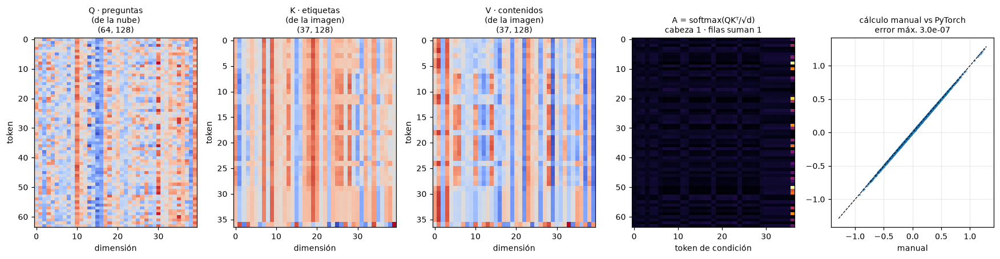

,tensor,cómo se obtiene,forma
0,Q,tokens de la nube · W_q,"(1, 64, 128)"
1,K,condición · W_k,"(1, 37, 128)"
2,V,condición · W_v,"(1, 37, 128)"
3,"Q, K, V por cabeza (4)",d_h = 32,"(1, 4, 64, 32)"
4,A (atención),softmax(QKᵀ/√d_h),"(1, 4, 64, 37)"
5,salida,A·V → W_o,"(1, 64, 128)"


In [13]:
# =============================================================================
# 6.1 · Q, K y V EXTRAÍDOS DE LOS PESOS Y VERIFICADOS
# =============================================================================
b0 = modelo.bloques[0]; mha = b0.cruz
D_, H_ = CFG["dim"], CFG["heads"]; dh = D_ // H_
with torch.no_grad():
    z, kp, _ = modelo.sa(xt)                                               # tokens de nube
    c = torch.cat([modelo.img(img0), modelo.t_mlp(timestep_embedding(t_io, D_)).unsqueeze(1)], 1)
    XQ, XKV = b0.n2(z), b0.nc(c)                                           # entradas normalizadas
    Wq, Wk, Wv = mha.in_proj_weight.chunk(3, 0); bq, bk, bv = mha.in_proj_bias.chunk(3, 0)
    Q, K, V = XQ @ Wq.T + bq, XKV @ Wk.T + bk, XKV @ Wv.T + bv              # las tres proyecciones
    M_, L_ = Q.shape[1], K.shape[1]
    Qh = Q.view(1, M_, H_, dh).transpose(1, 2); Kh = K.view(1, L_, H_, dh).transpose(1, 2)
    Vh = V.view(1, L_, H_, dh).transpose(1, 2)
    S_ = Qh @ Kh.transpose(-2, -1) / math.sqrt(dh)                          # compatibilidades
    A = S_.softmax(-1)                                                       # pesos de atención
    O = (A @ Vh).transpose(1, 2).reshape(1, M_, D_) @ mha.out_proj.weight.T + mha.out_proj.bias
    O_ref, A_ref = mha(XQ, XKV, XKV, need_weights=True, average_attn_weights=True)
err_salida = (O - O_ref).abs().max().item(); err_attn = (A.mean(1) - A_ref).abs().max().item()

fig = plt.figure(figsize=(16, 4.2))
for k, (nom, T_) in enumerate([("Q · preguntas\n(de la nube)", Q), ("K · etiquetas\n(de la imagen)", K),
                                ("V · contenidos\n(de la imagen)", V)]):
    a = fig.add_subplot(1, 5, k + 1); a.imshow(T_[0, :, :40].cpu(), aspect="auto", cmap="coolwarm"); a.grid(False)
    a.set_title(f"{nom}\n{tuple(T_.shape[1:])}", fontsize=9); a.set_xlabel("dimensión"); a.set_ylabel("token")
a = fig.add_subplot(1, 5, 4); a.imshow(A[0, 0].cpu(), aspect="auto", cmap="inferno"); a.grid(False)
a.set_title("A = softmax(QKᵀ/√d)\ncabeza 1 · filas suman 1", fontsize=9); a.set_xlabel("token de condición")
a = fig.add_subplot(1, 5, 5); a.scatter(O.flatten().cpu()[::5], O_ref.flatten().cpu()[::5], s=3, alpha=.4)
lim = float(O.abs().max()); a.plot([-lim, lim], [-lim, lim], "k--", lw=.8)
a.set_title(f"cálculo manual vs PyTorch\nerror máx. {err_salida:.1e}", fontsize=9); a.set_xlabel("manual")
plt.tight_layout(); guarda("qkv"); plt.show()

display(pd.DataFrame([("Q", "tokens de la nube · W_q", tuple(Q.shape)), ("K", "condición · W_k", tuple(K.shape)),
                      ("V", "condición · W_v", tuple(V.shape)), (f"Q, K, V por cabeza ({H_})", f"d_h = {dh}", tuple(Qh.shape)),
                      ("A (atención)", "softmax(QKᵀ/√d_h)", tuple(A.shape)), ("salida", "A·V → W_o", tuple(O.shape))],
                     columns=["tensor", "cómo se obtiene", "forma"]))
tarjeta("6.1 · Q, K y V con los pesos reales",
        "Las tres matrices de la atención cruzada del primer bloque, la matriz de atención resultante y la comparación "
        "entre el cálculo manual y la implementación de PyTorch.",
        [f"Q tiene {M_} filas (una por región de la nube); K y V tienen {L_} (parches + token t).",
         f"La matriz de atención mide {M_}×{L_} por cabeza.",
         f"Diferencia con PyTorch: <b>{err_salida:.1e}</b> → " +
         ("<b>coinciden</b>." if max(err_salida, err_attn) < 1e-4 else "revisar.")],
        ["Q nace SOLO de la nube y K, V SOLO de la imagen: la nube pregunta y la imagen responde.",
         "K y V salen del mismo tensor pero con matrices distintas: una decide quién es relevante, la otra qué información entrega.",
         "La verificación numérica garantiza que la explicación describe el cálculo real del modelo."],
        "Q pregunta, K responde a la pregunta, V entrega el contenido; y está comprobado contra PyTorch.")

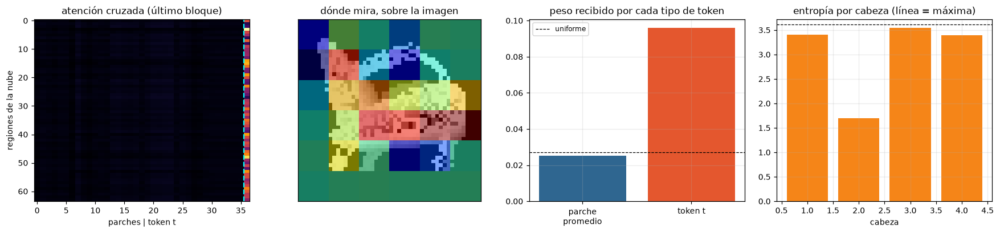

In [14]:
# =============================================================================
# 6.2 · ¿QUÉ MIRA EL MODELO? (atención cruzada + animación a lo largo de t)
# =============================================================================
n_it = L_ - 1; lado = int(round(math.sqrt(n_it)))
def mapa_atencion(t_val):
    with torch.no_grad():
        tt = torch.tensor([int(t_val)], device=DEVICE)
        _, Aw = modelo(DIF.q_sample(x0, tt, ruido), img0, tt,
                       descartar=torch.zeros(1, dtype=torch.bool, device=DEVICE), devolver_attn=True)
    Aw = Aw[0].cpu().numpy()
    return Aw, Aw[:, :n_it].mean(0).reshape(lado, lado)

Aw, mapa = mapa_atencion(int(DIF.T * .35))
ent = float(-(Aw * np.log(Aw + 1e-9)).sum(1).mean()); ent_max = math.log(Aw.shape[1])
peso_t = float(Aw[:, -1].mean()); unif = 1 / Aw.shape[1]
ocup = torch.nn.functional.avg_pool2d(torch.from_numpy((I_te[i_demo, 0] > 0).astype(np.float32))[None, None],
                                      CFG["img_size"] // lado)[0, 0].numpy()
corr = float(np.corrcoef(mapa.ravel(), ocup.ravel())[0, 1])
ent_cabezas = [float(-(A[0, h] * torch.log(A[0, h] + 1e-9)).sum(-1).mean()) for h in range(H_)]

fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
ax[0].imshow(Aw, aspect="auto", cmap="inferno"); ax[0].axvline(n_it - .5, color="cyan", ls="--"); ax[0].grid(False)
ax[0].set_title("atención cruzada (último bloque)"); ax[0].set_xlabel("parches | token t"); ax[0].set_ylabel("regiones de la nube")
ax[1].imshow(I_te[i_demo, 0], cmap="gray"); ax[1].imshow(np.kron(mapa, np.ones((CFG["img_size"] // lado,) * 2)), cmap="jet", alpha=.5)
ax[1].set_title("dónde mira, sobre la imagen"); ax[1].grid(False); ax[1].set_xticks([]); ax[1].set_yticks([])
ax[2].bar(["parche\npromedio", "token t"], [Aw[:, :n_it].mean(), peso_t], color=["#2f6690", "#e4572e"])
ax[2].axhline(unif, color="k", ls="--", lw=.8, label="uniforme"); ax[2].legend(fontsize=8)
ax[2].set_title("peso recibido por cada tipo de token")
ax[3].bar(range(1, H_ + 1), ent_cabezas, color="#f58518"); ax[3].axhline(ent_max, color="k", ls="--", lw=.8)
ax[3].set_title("entropía por cabeza (línea = máxima)"); ax[3].set_xlabel("cabeza")
plt.tight_layout(); guarda("atencion"); plt.show()

# --- animación: la atención según el nivel de ruido ------------------------------
ts_a = np.linspace(DIF.T - 1, 0, N_FRAMES).astype(int); mapas, ents = [], []
for t_ in ts_a:
    Aw_, m_ = mapa_atencion(t_); mapas.append(m_); ents.append(float(-(Aw_ * np.log(Aw_ + 1e-9)).sum(1).mean()))
fig_a, (u1, u2) = plt.subplots(1, 2, figsize=(9, 3.8)); vmn, vmx = min(m.min() for m in mapas), max(m.max() for m in mapas)
def _a(i):
    u1.clear(); u1.imshow(mapas[i], cmap="jet", vmin=vmn, vmax=vmx); u1.grid(False); u1.set_xticks([]); u1.set_yticks([])
    u1.set_title(f"atención por parche · t = {ts_a[i]}")
    u2.clear(); u2.plot(ts_a[:i + 1], ents[:i + 1], "o-"); u2.set_xlim(DIF.T, 0)
    u2.set_ylim(min(ents) * .995, max(ents) * 1.005); u2.set_xlabel("t (avanza el muestreo →)"); u2.set_title("entropía")
anima(fig_a, _a, len(ts_a), "02_atencion_vs_t")

selectiva = ent / ent_max < .9
if corr > .2:   lectura_corr = "la atención se concentra en los parches con silueta: consulta el objeto, no el fondo."
elif corr < -.2: lectura_corr = ("la atención se inclina hacia parches de <b>fondo</b>. Es un patrón conocido en Transformers "
                                 "(tokens «sumidero»): los parches uniformes sirven de ancla estable mientras la información "
                                 "útil viaja en V.")
else:           lectura_corr = "no hay preferencia espacial clara entre objeto y fondo."
tarjeta("6.2 · ¿Qué mira el modelo?",
        "Matriz de atención cruzada del último bloque, su proyección sobre la imagen, el peso que recibe el token temporal "
        "y la entropía de cada cabeza. La animación recorre distintos niveles de ruido.",
        [f"Entropía media: {ent:.2f} de {ent_max:.2f} posibles (<b>{100*ent/ent_max:.0f} %</b>): atención "
         + ("selectiva." if selectiva else "casi uniforme entre parches."),
         f"El token temporal recibe <b>{peso_t/unif:.1f}×</b> el peso uniforme ({peso_t:.3f} frente a {unif:.3f}).",
         f"Correlación entre atención y silueta: <b>{corr:+.2f}</b>."],
        [("Una atención casi uniforme funciona como un <b>resumen global</b> de la imagen: el promedio de V ya "
          "distingue un avión de una silla. La mejora de la sección 8 confirma que la información visual sí llega."
          if not selectiva else "La atención elige parches concretos: el modelo localiza la información visual."),
         f"Correlación con la silueta: {lectura_corr}",
         "El token temporal es el más consultado: antes de corregir, el modelo necesita saber cuánto ruido queda."],
        "El modelo presta especial atención al paso t y usa la imagen como resumen global; con más entrenamiento la atención se vuelve más selectiva.")

# 7 · ¿Por qué la arquitectura es innovadora?

| | PC² (2023, antecesor) | TrDPNet (2025) |
|---|---|---|
| Cómo entra la imagen | se **proyecta** sobre la nube con la pose de cámara | es **memoria consultable** (K, V) |
| Qué puntos la reciben | solo los visibles desde la cámara | **todos** los tokens |
| Dónde se usa | una vez por paso, de forma local | en los **L bloques** y los **T pasos** |
| Red que predice el ruido | U-Net sobre PointNet | **Transformer** |
| F-score@0.01 reportado (ShapeNet-R2N2) | 0.309 | **0.389** (+26 %) |

**Tres innovaciones:**
1. **Atención cruzada como control condicional**, en lugar de proyección geométrica: resuelve la inestabilidad del control en PC².
2. **Tokenización geométrica** (capa SA) que hace viable un Transformer sobre nubes grandes.
3. **Predictor de ruido basado en Transformer**, al que el artículo atribuye la mejora de más del 20 %.

**Lo heredado, para ser precisos:** la difusión (DDPM), la guía sin clasificador y el muestreo del punto más lejano ya existían. La contribución está en **cómo se combinan**.

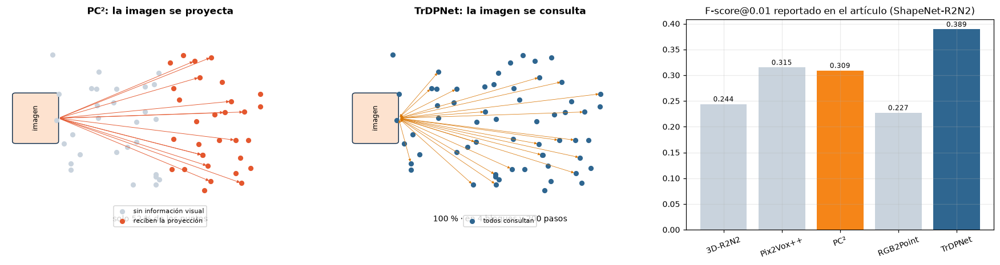

In [15]:
# =============================================================================
# 7 · INNOVACIÓN: PROYECCIÓN (PC²) FRENTE A ATENCIÓN CRUZADA (TrDPNet)
# =============================================================================
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
rng_e = np.random.default_rng(3); pts = rng_e.uniform(1.5, 8.5, size=(60, 2)); vis = pts[:, 0] > 5.2
for a, tit in zip(ax[:2], ["PC²: la imagen se proyecta", "TrDPNet: la imagen se consulta"]):
    a.set_xlim(0, 10); a.set_ylim(0, 10); a.axis("off"); a.set_title(tit, fontsize=11, weight="bold")
    a.add_patch(FancyBboxPatch((.3, 4.2), 1.3, 2.2, boxstyle="round,pad=.1", fc="#fde2cf", ec="#16324f"))
    a.text(.95, 5.3, "imagen", rotation=90, ha="center", va="center", fontsize=8)
ax[0].scatter(pts[~vis, 0], pts[~vis, 1], s=25, c="#c9d3dd", label="sin información visual")
ax[0].scatter(pts[vis, 0], pts[vis, 1], s=25, c="#e4572e", label="reciben la proyección")
for q in pts[vis][:12]: ax[0].add_patch(FancyArrowPatch((1.7, 5.3), q, arrowstyle="-|>", mutation_scale=7, color="#e4572e", lw=.6))
ax[0].legend(fontsize=7, loc="lower center"); ax[0].text(5, .4, f"solo {vis.mean()*100:.0f} % de los puntos", ha="center")
ax[1].scatter(pts[:, 0], pts[:, 1], s=25, c="#2f6690", label="todos consultan")
for q in pts[::3]: ax[1].add_patch(FancyArrowPatch((1.7, 5.3), q, arrowstyle="<|-|>", mutation_scale=6, color="#d97706", lw=.5))
ax[1].legend(fontsize=7, loc="lower center"); ax[1].text(5, .4, f"100 % · en {CFG['depth']} bloques y {DIF.T} pasos", ha="center")
met = {"3D-R2N2": .244, "Pix2Vox++": .315, "PC²": .309, "RGB2Point": .227, "TrDPNet": .389}
ax[2].bar(list(met), list(met.values()), color=["#c9d3dd"] * 2 + ["#f58518", "#c9d3dd", "#2f6690"])
for i, v in enumerate(met.values()): ax[2].text(i, v + .005, f"{v:.3f}", ha="center", fontsize=8)
ax[2].set_title("F-score@0.01 reportado en el artículo (ShapeNet-R2N2)"); ax[2].tick_params(axis="x", rotation=20)
plt.tight_layout(); guarda("innovacion"); plt.show()

tarjeta("7 · Innovación",
        "Esquema del control condicional por proyección (PC²) frente a la atención cruzada (TrDPNet) y los resultados "
        "reportados por el artículo frente a métodos previos.",
        [f"Con proyección solo una parte de la nube recibe información visual ({vis.mean()*100:.0f} % en el esquema).",
         "Con atención cruzada todos los tokens la reciben, en cada bloque y cada paso.",
         "Según el artículo: +26 % frente a PC² y +71 % frente a RGB2Point."],
        ["La innovación no es «usar un Transformer», sino <b>convertir la imagen en memoria consultable</b>.",
         "Las cifras de la derecha son del artículo; la comprobación propia del mecanismo está en la sección 8."],
        "En PC² la imagen se pega a los puntos visibles; en TrDPNet toda la nube la consulta en cada paso.")

# 8 · Inferencia funcional y resultados

## El Algoritmo 2 del artículo, tal como se ejecuta

1. Se toma la imagen de entrada.
2. Se empieza con una nube de ruido gaussiano X_T.
3. Para t = T … 1: el modelo predice el ruido **dos veces** (con imagen y con el token nulo) y se combinan con la **guía sin clasificador**:  ε̂ = ε(∅) + ω·(ε(imagen) − ε(∅)).
4. Se resta el ruido (Ecuación 4) y se repite.

La animación muestra exactamente ese proceso para una imagen del conjunto de prueba.

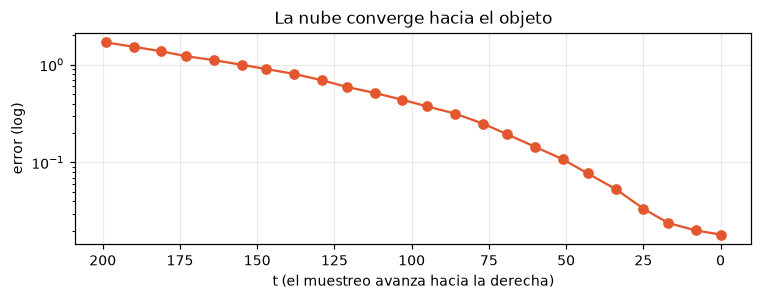

In [16]:
# =============================================================================
# 8.1 · INFERENCIA: LA NUBE EMERGE DEL RUIDO
# =============================================================================
marcas = set(np.linspace(0, DIF.T - 1, N_FRAMES).astype(int).tolist())
t0 = time.time()
pred, snaps = muestrea(modelo, img0, CFG["n_puntos"], DIF, omega=CFG["omega"], guardar=marcas, semilla=7)
t_inf = time.time() - t0
ts_m = sorted(snaps, reverse=True); gt0 = X_te[i_demo].numpy()
cds = [float((torch.cdist(torch.from_numpy(snaps[t_]), X_te[i_demo:i_demo+1]).min(2).values ** 2).mean()) for t_ in ts_m]

fig_m = plt.figure(figsize=(12, 4)); m1 = fig_m.add_subplot(1, 3, 1)
m2 = fig_m.add_subplot(1, 3, 2, projection="3d"); m3 = fig_m.add_subplot(1, 3, 3, projection="3d")
def _m(i):
    t_ = ts_m[i]; q = snaps[t_][0]
    m1.clear(); m1.imshow(IMG_te[i_demo, 0], cmap="magma"); m1.grid(False); m1.set_xticks([]); m1.set_yticks([])
    m1.set_title("única entrada"); m1.set_xlabel(f"paso {DIF.T - t_} de {DIF.T}")
    m2.clear(); m2.scatter(q[:, 0], q[:, 2], q[:, 1], s=1.2, c=q[:, 1], cmap="coolwarm"); lim = max(.8, float(np.abs(q).max()))
    m2.set_xlim(-lim, lim); m2.set_ylim(-lim, lim); m2.set_zlim(-lim, lim); m2.view_init(18, 35); m2.set_title(f"reconstrucción · t = {t_}")
    m2.set_xticklabels([]); m2.set_yticklabels([]); m2.set_zticklabels([])
    m3.clear(); m3.scatter(gt0[:, 0], gt0[:, 2], gt0[:, 1], s=1.2, c="#54a24b"); m3.view_init(18, 35)
    m3.set_xlim(-.8, .8); m3.set_ylim(-.8, .8); m3.set_zlim(-.8, .8); m3.set_title("objeto real")
    m3.set_xticklabels([]); m3.set_yticklabels([]); m3.set_zticklabels([])
anima(fig_m, _m, len(ts_m), "03_nube_emerge")

fig, ax = plt.subplots(figsize=(7, 2.8)); ax.plot(ts_m, cds, "o-", color="#e4572e"); ax.invert_xaxis(); ax.set_yscale("log")
ax.set_xlabel("t (el muestreo avanza hacia la derecha)"); ax.set_ylabel("error (log)"); ax.set_title("La nube converge hacia el objeto")
plt.tight_layout(); guarda("convergencia"); plt.show()
tarjeta("8.1 · Inferencia funcional",
        "Reconstrucción completa de un objeto a partir de una sola imagen, del ruido puro al resultado final.",
        [f"Tiempo de inferencia: <b>{t_inf:.1f} s</b> en {DEVICE} ({DIF.T} pasos × 2 evaluaciones).",
         f"Error: {cds[0]:.4f} al inicio → <b>{cds[-1]:.4f}</b> al final ({100*(1-cds[-1]/max(cds[0],1e-9)):.0f} % menos).",
         "La forma global aparece en la primera mitad; la segunda solo afina."],
        ["La caída rápida del error al principio indica que el modelo decide primero <b>qué objeto es</b> y después los detalles.",
         "La zona plana final explica por qué existen muestreadores acelerados (DDIM) que saltan pasos."],
        "Partiendo de ruido, con una sola imagen, el modelo reconstruye el objeto en segundos.")

Evaluación completa en 107 s (guardada en resultados.json)


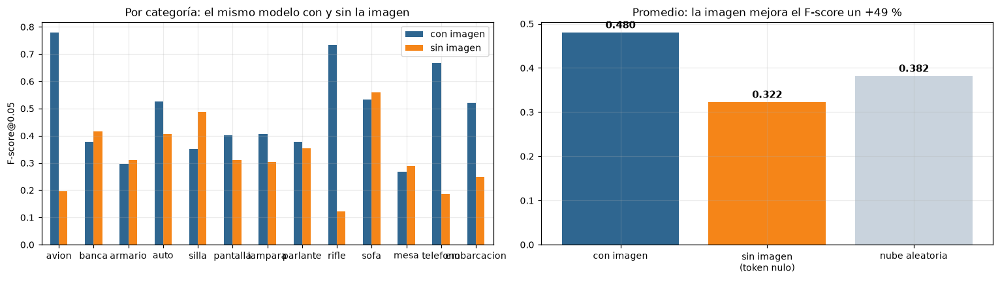

,con imagen,sin imagen
avion,0.779000,0.197000
banca,0.379000,0.416000
armario,0.296000,0.311000
auto,0.526000,0.406000
silla,0.351000,0.488000
pantalla,0.403000,0.310000
lampara,0.406000,0.303000
parlante,0.379000,0.353000
rifle,0.734000,0.123000
sofa,0.533000,0.560000


In [17]:
# =============================================================================
# 8.2 · RESULTADOS POR CATEGORÍA Y PRUEBA DE QUE LA IMAGEN IMPORTA
# =============================================================================
def evalua(modelo, omega, n_por_cat, semilla=11, usar_condicion=True):
    res = []
    for ci, c in enumerate(CATS):
        ids = np.where(Y_te == ci)[0][:n_por_cat]
        if len(ids) == 0: continue
        img = IMG_te[ids].to(DEVICE); gt = X_te[ids].to(DEVICE)
        if usar_condicion:
            pred, _ = muestrea(modelo, img, CFG["n_puntos"], DIF, omega=omega, semilla=semilla)
        else:   # incondicional: se alimenta el token nulo en las dos ramas
            with torch.no_grad():
                torch.manual_seed(semilla)
                x = torch.randn(len(ids), CFG["n_puntos"], 3, device=DEVICE)
                unc = torch.ones(len(ids), dtype=torch.bool, device=DEVICE)
                for i in reversed(range(DIF.T)):
                    t = torch.full((len(ids),), i, device=DEVICE, dtype=torch.long)
                    e, _ = modelo(x, img, t, descartar=unc)
                    a, ab = DIF.alphas[i], DIF.ab[i]
                    x = (x - (1 - a) / (1 - ab).sqrt() * e) / a.sqrt()
                    if i > 0: x = x + DIF.betas[i].sqrt() * torch.randn_like(x)
                pred = x
        f, p, r = f_score(pred, gt, CFG["tau"]); cd = chamfer(pred, gt)
        for j in range(len(ids)):
            res.append(dict(categoria=c, F=f[j].item(), P=p[j].item(), R=r[j].item(), CD=cd[j].item()))
    return pd.DataFrame(res)

RUTA_RES = BASE / "outputs" / "resultados.json"
if EVALUACION_COMPLETA or not RUTA_RES.exists():
    t0 = time.time()
    d_c = evalua(modelo, CFG["omega"], CFG["n_eval_por_cat"])
    d_u = evalua(modelo, 1.0, CFG["n_eval_por_cat"], usar_condicion=False)
    torch.manual_seed(3); fr = []
    for i in range(len(CATS)):
        g = X_te[np.where(Y_te == i)[0][:CFG["n_eval_por_cat"]]]
        fr += f_score(torch.randn_like(g) * g.std(), g, CFG["tau"])[0].tolist()
    R = {"F_cond": float(d_c.F.mean()), "F_unc": float(d_u.F.mean()), "F_rnd": float(np.mean(fr)),
         "CD_cond": float(d_c.CD.mean()), "CD_unc": float(d_u.CD.mean()),
         "por_cat": {c: [float(d_c[d_c.categoria == c].F.mean()), float(d_u[d_u.categoria == c].F.mean())] for c in CATS},
         "tau": CFG["tau"], "segundos": time.time() - t0, "dispositivo": str(DEVICE)}
    json.dump(R, open(RUTA_RES, "w"), indent=2)
    print(f"Evaluación completa en {R['segundos']:.0f} s (guardada en {RUTA_RES.name})")
else:
    R = json.load(open(RUTA_RES)); print(f"Métricas cargadas de {RUTA_RES.name} (modo sustentación)")
F_COND, F_UNC, F_RND = R["F_cond"], R["F_unc"], R["F_rnd"]; CD_COND, CD_UNC = R["CD_cond"], R["CD_unc"]
GAN = 100 * (F_COND / max(F_UNC, 1e-9) - 1)

tab = pd.DataFrame(R["por_cat"], index=["con imagen", "sin imagen"]).T.round(3)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
tab.plot(kind="bar", ax=ax[0], color=["#2f6690", "#f58518"], rot=0); ax[0].set_ylabel(f"F-score@{CFG['tau']}")
ax[0].set_title("Por categoría: el mismo modelo con y sin la imagen")
barras = {"con imagen": F_COND, "sin imagen\n(token nulo)": F_UNC, "nube aleatoria": F_RND}
ax[1].bar(list(barras), list(barras.values()), color=["#2f6690", "#f58518", "#c9d3dd"])
for i, v in enumerate(barras.values()): ax[1].text(i, v + .01, f"{v:.3f}", ha="center", fontsize=10, weight="bold")
ax[1].set_title(f"Promedio: la imagen mejora el F-score un {GAN:+.0f} %")
plt.tight_layout(); guarda("resultados"); plt.show()
display(tab.style.background_gradient(cmap="Blues", axis=None))

mejor, peor = tab["con imagen"].idxmax(), tab["con imagen"].idxmin()
tarjeta("8.2 · ¿La imagen realmente guía la reconstrucción?",
        "F-score del mismo modelo con la imagen y con el token nulo (sin imagen), por categoría y en promedio, junto a "
        "una nube aleatoria como referencia mínima.",
        [f"Con imagen: <b>{F_COND:.3f}</b> · sin imagen: {F_UNC:.3f} · aleatoria: {F_RND:.3f}.",
         f"Ganancia por usar la imagen: <b>{GAN:+.1f} %</b>; Chamfer {CD_UNC:.4f} → {CD_COND:.4f}.",
         f"Mejor categoría: <b>{mejor}</b> ({tab.loc[mejor,'con imagen']:.3f}); más difícil: <b>{peor}</b> ({tab.loc[peor,'con imagen']:.3f})."],
        ["Es una comparación limpia: mismo modelo, mismos datos; solo cambia si se consulta la imagen. "
         "La diferencia es el efecto de la atención cruzada.",
         f"Sin imagen el modelo cae hacia una forma promedio; por eso {tab['sin imagen'].idxmax()} obtiene el mejor "
         "valor sin condición: es la categoría más parecida a esa forma media.",
         f"{peor} es la más difícil: estructuras finas (patas, bordes) ocupan pocos puntos y se pierden con facilidad."],
        f"Con la imagen, el F-score pasa de {F_UNC:.2f} a {F_COND:.2f}: la atención cruzada funciona.")

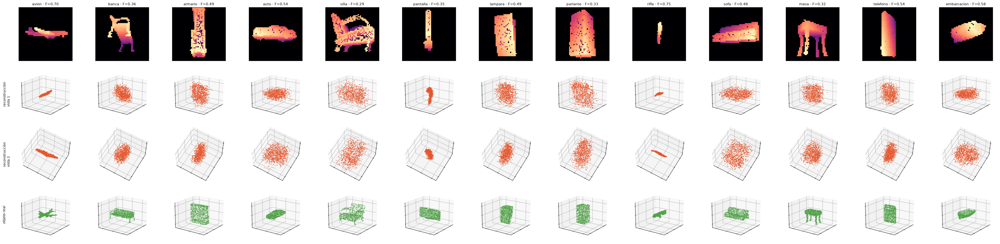

In [18]:
# =============================================================================
# 8.3 · CALIDAD VISUAL: DOS PERSPECTIVAS Y ÓRBITA 3D
# =============================================================================
ids = [int(np.where(Y_te == i)[0][0]) for i in range(len(CATS))]
pv, _ = muestrea(modelo, IMG_te[ids].to(DEVICE), CFG["n_puntos"], DIF, omega=CFG["omega"], semilla=5)
pv = pv.cpu().numpy(); gv = X_te[ids].numpy()
fv = f_score(torch.from_numpy(pv), torch.from_numpy(gv), CFG["tau"])[0].numpy()
fig = plt.figure(figsize=(3 * len(CATS), 9.5))
for j, c in enumerate(CATS):
    a = fig.add_subplot(4, len(CATS), j + 1); a.imshow(IMG_te[ids[j], 0], cmap="magma")
    a.set_xticks([]); a.set_yticks([]); a.grid(False); a.set_title(f"{c} · F={fv[j]:.2f}", fontsize=10)
    for r, (q, col, vista) in enumerate([(pv[j], "#e4572e", (18, 35)), (pv[j], "#e4572e", (60, 120)), (gv[j], "#54a24b", (18, 35))]):
        b = fig.add_subplot(4, len(CATS), (r + 1) * len(CATS) + j + 1, projection="3d")
        b.scatter(q[:, 0], q[:, 2], q[:, 1], s=1, c=col); b.view_init(*vista)
        b.set_xlim(-.7, .7); b.set_ylim(-.7, .7); b.set_zlim(-.7, .7)
        b.set_xticklabels([]); b.set_yticklabels([]); b.set_zticklabels([])
        if j == 0: b.text2D(-.3, .5, ["reconstrucción\nvista 1", "reconstrucción\nvista 2", "objeto real"][r],
                            transform=b.transAxes, rotation=90, va="center", fontsize=9)
plt.tight_layout(); guarda("cualitativo"); plt.show()

fig_o = plt.figure(figsize=(9, 4)); o1 = fig_o.add_subplot(1, 2, 1, projection="3d"); o2 = fig_o.add_subplot(1, 2, 2, projection="3d")
jo = int(np.argmax(fv))
def _o(i):
    for a, q, col, tt in [(o1, pv[jo], "#e4572e", "reconstrucción"), (o2, gv[jo], "#54a24b", "objeto real")]:
        a.clear(); a.scatter(q[:, 0], q[:, 2], q[:, 1], s=1.2, c=col); a.view_init(16, 360 * i / N_FRAMES)
        a.set_xlim(-.7, .7); a.set_ylim(-.7, .7); a.set_zlim(-.7, .7); a.set_title(f"{tt} · {CATS[jo]}")
        a.set_xticklabels([]); a.set_yticklabels([]); a.set_zticklabels([])
anima(fig_o, _o, N_FRAMES, "04_orbita")
tarjeta("8.3 · Calidad visual",
        "Cada columna es una categoría: imagen de entrada, reconstrucción desde dos ángulos y objeto real. "
        "La órbita gira 360° sobre la mejor reconstrucción.",
        [f"F-score por objeto: " + ", ".join(f"{c} {v:.2f}" for c, v in zip(CATS, fv)) + ".",
         "La segunda perspectiva revela lo que la vista frontal oculta: grosor y profundidad."],
        ["La silueta suele reconstruirse bien; la profundidad es el punto débil típico de la vista única.",
         "Girar el objeto es la prueba honesta: una reconstrucción puede verse bien de frente y estar aplanada de lado."],
        "La reconstrucción se juzga girándola, no desde el ángulo de la cámara.")

  ω = 1.0: F = 0.436
  ω = 2.0: F = 0.504
  ω = 3.0: F = 0.498
  ω = 5.0: F = 0.466


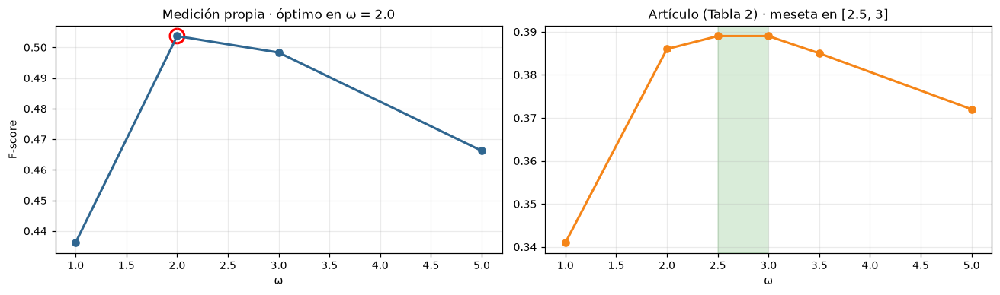

In [19]:
# =============================================================================
# 8.4 · EFECTO DE LA ESCALA DE GUÍA ω
# =============================================================================
RUTA_W = BASE / "outputs" / "omega.json"
if EVALUACION_COMPLETA or not RUTA_W.exists():
    Wres = {}
    for w in CFG["omegas_ablacion"]:
        d = evalua(modelo, w, max(1, CFG["n_eval_por_cat"] - 1), semilla=21); Wres[str(w)] = float(d.F.mean())
        print(f"  ω = {w}: F = {Wres[str(w)]:.3f}", flush=True)
    json.dump(Wres, open(RUTA_W, "w"), indent=2)
else:
    Wres = json.load(open(RUTA_W))
ws = [float(k) for k in Wres]; fs = list(Wres.values()); w_best = ws[int(np.argmax(fs))]
PAPER_T2 = {1.0: .341, 2.0: .386, 2.5: .389, 3.0: .389, 3.5: .385, 5.0: .372}
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(ws, fs, "o-", lw=2, color="#2f6690"); ax[0].scatter([w_best], [max(fs)], s=150, facecolor="none", edgecolor="red", lw=2)
ax[0].set_xlabel("ω"); ax[0].set_ylabel("F-score"); ax[0].set_title(f"Medición propia · óptimo en ω = {w_best}")
ax[1].plot(list(PAPER_T2), list(PAPER_T2.values()), "o-", lw=2, color="#f58518"); ax[1].axvspan(2.5, 3, alpha=.15, color="green")
ax[1].set_xlabel("ω"); ax[1].set_title("Artículo (Tabla 2) · meseta en [2.5, 3]")
plt.tight_layout(); guarda("omega"); plt.show()
tarjeta("8.4 · Escala de guía ω",
        "F-score en función de ω, que regula cuánto se amplifica la diferencia entre la predicción con imagen y sin ella.",
        [f"Óptimo propio en <b>ω = {w_best}</b>; el artículo encuentra la meseta en [2.5, 3.0].",
         f"Con ω = 1 (sin guía) F = {Wres.get('1.0', fs[0]):.3f}; con el valor más alto, F = {fs[-1]:.3f}.",
         "Ambas curvas tienen forma de U invertida."],
        ["ω bajo: la imagen influye poco y aparecen formas genéricas.",
         "ω alto: la guía exagera la condición, la nube se deforma y cae el <i>recall</i>.",
         "Que el óptimo propio sea algo menor que el del artículo es coherente con un modelo más pequeño."],
        "Hay un punto dulce de guía; demasiada guía también estropea la forma.")

## 8.5 · Tabla consolidada de métricas

**Qué hace:** reúne en un solo lugar todas las cifras obtenidas en las secciones anteriores —calidad de reconstrucción, efecto de la imagen, efecto de la guía, coste de cómputo y verificación de los tensores— y las compara con las que publica el artículo (Tablas 1 y 2).

**Cómo leerla:** la columna *valor propio* corresponde a esta ejecución; la columna *artículo* es la referencia publicada. No son directamente comparables (el modelo de referencia es unas cien veces mayor y se entrena 300 000 pasos), pero sí lo son las **tendencias**: qué categorías resultan fáciles o difíciles y cómo se comporta la guía.

La celda exporta además `latex/tabla_metricas.tex`, que el informe incluye automáticamente.

métrica,valor propio,artículo,qué mide
F-score@0.05 · con imagen,0.480,0.389,calidad de la reconstrucción condicionada
F-score@0.05 · sin imagen,0.322,—,el mismo modelo con el token nulo
F-score@0.05 · nube aleatoria,0.382,—,suelo de referencia
Ganancia por usar la imagen,+48.8 %,—,efecto medible de la atención cruzada
Distancia de Chamfer · con imagen,0.0222,—,error geométrico medio
Distancia de Chamfer · sin imagen,0.0341,—,error sin condición
Escala de guía óptima ω,2.0,2.5 – 3.0,punto dulce de la guía sin clasificador
"Error de Q, K y V frente a PyTorch",3.0e-07,—,verificación del mecanismo de atención
Entropía de la atención cruzada,98 %,—,cuán repartida está la atención
Peso del token temporal,3.6×,—,veces por encima del reparto uniforme


,F con imagen,F sin imagen,ganancia (%),F artículo
avion,0.779,0.197,294.851,0.576
banca,0.379,0.416,-8.847,0.441
armario,0.296,0.311,-4.556,0.319
auto,0.526,0.406,29.638,0.428
silla,0.351,0.488,-28.124,0.337
pantalla,0.403,0.310,30.159,0.258
lampara,0.406,0.303,33.818,0.357
parlante,0.379,0.353,7.363,0.221
rifle,0.734,0.123,495.846,0.582
sofa,0.533,0.560,-4.858,0.272


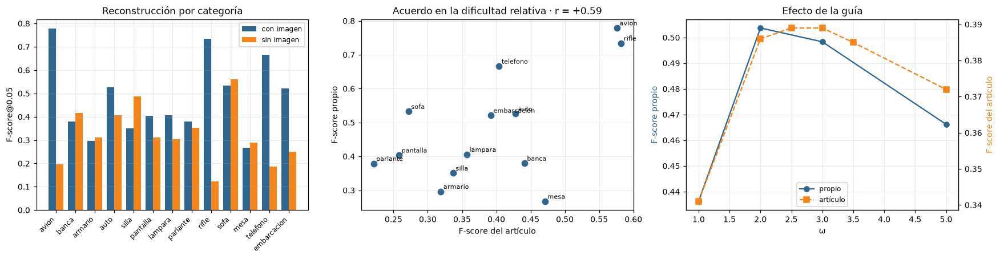

Exportado: outputs/metricas_*.csv y latex/tabla_metricas.tex


In [20]:
# =============================================================================
# 8.5 · CONSOLIDACIÓN DE TODAS LAS MÉTRICAS
# =============================================================================
PAPER_T1 = {"avion": .576, "banca": .441, "armario": .319, "auto": .428, "silla": .337, "pantalla": .258,
            "lampara": .357, "parlante": .221, "rifle": .582, "sofa": .272, "mesa": .471, "telefono": .404,
            "embarcacion": .392}                      # Tabla 1 del artículo (TrDPNet)

# ---- tabla 1 · métricas globales ---------------------------------------------
globales = pd.DataFrame([
    ("F-score@%s · con imagen" % CFG["tau"], f"{F_COND:.3f}", "0.389", "calidad de la reconstrucción condicionada"),
    ("F-score@%s · sin imagen" % CFG["tau"], f"{F_UNC:.3f}", "—", "el mismo modelo con el token nulo"),
    ("F-score@%s · nube aleatoria" % CFG["tau"], f"{F_RND:.3f}", "—", "suelo de referencia"),
    ("Ganancia por usar la imagen", f"{GAN:+.1f} %", "—", "efecto medible de la atención cruzada"),
    ("Distancia de Chamfer · con imagen", f"{CD_COND:.4f}", "—", "error geométrico medio"),
    ("Distancia de Chamfer · sin imagen", f"{CD_UNC:.4f}", "—", "error sin condición"),
    ("Escala de guía óptima ω", f"{w_best}", "2.5 – 3.0", "punto dulce de la guía sin clasificador"),
    ("Error de Q, K y V frente a PyTorch", f"{err_salida:.1e}", "—", "verificación del mecanismo de atención"),
    ("Entropía de la atención cruzada", f"{100*ent/ent_max:.0f} %", "—", "cuán repartida está la atención"),
    ("Peso del token temporal", f"{peso_t/unif:.1f}×", "—", "veces por encima del reparto uniforme"),
    ("Parámetros del modelo", f"{n_par:,}".replace(",", " "), "≈ 100 M", "tamaño de la réplica"),
    ("Tiempo de inferencia por objeto", f"{t_inf:.1f} s", "—", f"en {DEVICE}, {DIF.T} pasos × 2 evaluaciones"),
    ("Origen de los datos", str(CFG.get("datos", "—")), "ShapeNet-R2N2", "conjunto empleado"),
], columns=["métrica", "valor propio", "artículo", "qué mide"])
display(globales.style.hide(axis="index").set_properties(**{"text-align": "left"}))

# ---- tabla 2 · por categoría --------------------------------------------------
porcat = pd.DataFrame({
    "F con imagen": [R["por_cat"][c][0] for c in CATS],
    "F sin imagen": [R["por_cat"][c][1] for c in CATS],
    "ganancia (%)": [100 * (R["por_cat"][c][0] / max(R["por_cat"][c][1], 1e-9) - 1) for c in CATS],
    "F artículo": [PAPER_T1.get(c, np.nan) for c in CATS]}, index=CATS).round(3)
porcat.loc["promedio"] = porcat.mean().round(3)
display(porcat.style.background_gradient(cmap="Blues", subset=["F con imagen"])
        .background_gradient(cmap="Oranges", subset=["ganancia (%)"]).format("{:.3f}"))

comunes = [c for c in CATS if c in PAPER_T1]
rho_paper = (float(np.corrcoef([R["por_cat"][c][0] for c in comunes], [PAPER_T1[c] for c in comunes])[0, 1])
             if len(comunes) > 2 else float("nan"))

# ---- figura resumen -----------------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
idx = np.arange(len(CATS)); anc = .38
ax[0].bar(idx - anc / 2, porcat["F con imagen"][:-1], anc, label="con imagen", color="#2f6690")
ax[0].bar(idx + anc / 2, porcat["F sin imagen"][:-1], anc, label="sin imagen", color="#f58518")
ax[0].set_xticks(idx); ax[0].set_xticklabels(CATS, rotation=45, ha="right", fontsize=8)
ax[0].set_ylabel(f"F-score@{CFG['tau']}"); ax[0].legend(fontsize=8); ax[0].set_title("Reconstrucción por categoría")
if len(comunes) > 2:
    xs = [PAPER_T1[c] for c in comunes]; ys = [R["por_cat"][c][0] for c in comunes]
    ax[1].scatter(xs, ys, s=45, color="#2f6690")
    for c, x, y in zip(comunes, xs, ys): ax[1].annotate(c, (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax[1].set_xlabel("F-score del artículo"); ax[1].set_ylabel("F-score propio")
    ax[1].set_title(f"Acuerdo en la dificultad relativa · r = {rho_paper:+.2f}")
else:
    ax[1].axis("off"); ax[1].text(.5, .5, "categorías insuficientes\npara comparar con el artículo", ha="center")
ax[2].plot([float(k) for k in Wres], list(Wres.values()), "o-", color="#2f6690", label="propio")
ax[2].set_xlabel("ω"); ax[2].set_ylabel("F-score propio", color="#2f6690"); ax[2].set_title("Efecto de la guía")
ax2 = ax[2].twinx(); ax2.grid(False)
ax2.plot(list(PAPER_T2), list(PAPER_T2.values()), "s--", color="#f58518", label="artículo")
ax2.set_ylabel("F-score del artículo", color="#f58518")
ax[2].plot([], [], "s--", color="#f58518", label="artículo"); ax[2].legend(fontsize=8, loc="lower center")
plt.tight_layout(); guarda("tabla_metricas"); plt.show()

# ---- exportación --------------------------------------------------------------
porcat.to_csv(BASE / "outputs" / "metricas_por_categoria.csv")
globales.to_csv(BASE / "outputs" / "metricas_globales.csv", index=False)
def _tex(x):
    t = str(x).replace("%", "\\%").replace("×", "$\\times$").replace("ω", "$\\omega$")
    return t.replace("—", "--").replace("≈", "$\\approx$").replace("–", "--").replace("·", "\\textperiodcentered{}")
filas_g = "\n".join(f"{_tex(r['métrica'])} & {_tex(r['valor propio'])} & {_tex(r['artículo'])} \\\\"
                    for _, r in globales.iterrows())
filas_c = "\n".join(f"{c} & {porcat.loc[c, 'F con imagen']:.3f} & {porcat.loc[c, 'F sin imagen']:.3f} & "
                    f"{porcat.loc[c, 'ganancia (%)']:+.0f} & "
                    + (f"{porcat.loc[c, 'F artículo']:.3f}" if not np.isnan(porcat.loc[c, "F artículo"]) else "--")
                    + " \\\\" for c in list(CATS) + ["promedio"])
tex = ("% Generado por el notebook · " + time.strftime("%Y-%m-%d %H:%M") + "\n"
       "\\begin{table}[H]\\centering\\footnotesize\n\\caption{Métricas globales de la ejecución propia.}\n"
       "\\label{tab:metricas-globales}\n\\begin{tabular}{lcc}\\toprule\n"
       "Métrica & Valor propio & Artículo \\\\\\midrule\n" + filas_g + "\n\\bottomrule\\end{tabular}\\end{table}\n\n"
       "\\begin{table}[H]\\centering\\footnotesize\n\\caption{Resultados por categoría.}\n"
       "\\label{tab:metricas-categoria}\n\\begin{tabular}{lcccc}\\toprule\n"
       "Categoría & F con imagen & F sin imagen & Ganancia (\\%) & F artículo \\\\\\midrule\n"
       + filas_c + "\n\\bottomrule\\end{tabular}\\end{table}\n")
(BASE / "latex" / "tabla_metricas.tex").write_text(tex, encoding="utf-8")
print("Exportado: outputs/metricas_*.csv y latex/tabla_metricas.tex")

facil = porcat.iloc[:-1]["F con imagen"].idxmax(); dificil = porcat.iloc[:-1]["F con imagen"].idxmin()
mas_gana = porcat.iloc[:-1]["ganancia (%)"].idxmax()
tarjeta("8.5 · Todas las métricas en una tabla",
        "Consolidación de las cifras de las secciones 3 a 8: calidad, efecto de la imagen, efecto de la guía, "
        "coste de cómputo y verificación de los tensores, junto a la referencia publicada.",
        [f"Promedio propio: <b>{F_COND:.3f}</b> con imagen frente a {F_UNC:.3f} sin ella ({GAN:+.1f} %).",
         f"Categoría mejor reconstruida: <b>{facil}</b>; más difícil: <b>{dificil}</b>; la que más gana con la "
         f"imagen: <b>{mas_gana}</b>.",
         (f"Correlación con el orden de dificultad del artículo: <b>r = {rho_paper:+.2f}</b>."
          if len(comunes) > 2 else "Pocas categorías comunes con el artículo para correlacionar."),
         f"Coste: {t_inf:.1f} s por objeto en {DEVICE} con {n_par:,} parámetros."],
        ["El valor absoluto es menor que el del artículo, y debe serlo: la réplica tiene una fracción de los "
         "parámetros y entrena en minutos en lugar de días. Lo comparable es el <b>patrón</b>.",
         "Que las categorías fáciles y difíciles coincidan con las del artículo indica que la dificultad "
         "proviene de la geometría (piezas finas, simetrías, ambigüedad de la vista única) y no de la "
         "implementación.",
         "La ganancia por usar la imagen y el óptimo de ω son las dos cifras que demuestran que el mecanismo "
         "condicional funciona tal como lo describe el artículo."],
        "Una sola tabla responde a «¿funciona?», «¿cuánto aporta la imagen?» y «¿coincide con el artículo?».")

# 9 · Interfaz interactiva: cargar una imagen y ver la reconstrucción

## Qué archivo se carga

| Archivo | Obligatorio | Formatos | Para qué |
|---|---|---|---|
| **Imagen de entrada** | sí | `.png` `.jpg` `.jpeg` `.bmp` `.tif` `.npy` | es lo que se reconstruye |
| Nube de referencia | no | `.ply` `.npy` `.csv` `.txt` | solo para calcular métricas |
| Pesos del modelo | sí (ya cargado) | `.pt` | `weights/trdpnet_replica.pt` |

La imagen se convierte a escala de grises y se redimensiona al tamaño del modelo. **El modelo espera imágenes como las del conjunto**: fondo negro y objeto claro de una de las categorías. La celda guarda automáticamente ejemplos listos para probar en `ejemplos/` (imagen `.png` + nube `.ply`), de modo que la demostración nunca depende de buscar archivos en vivo.

Además se genera la aplicación **Streamlit** (`streamlit_app/app.py`), la interfaz web recomendada por el enunciado.

Ejemplos listos para cargar: armario.ply, armario.png, auto.ply, auto.png, avion.ply, avion.png, banca.ply, banca.png, embarcacion.ply, embarcacion.png, lampara.ply, lampara.png, mesa.ply, mesa.png, pantalla.ply, pantalla.png, parlante.ply, parlante.png, rifle.ply, rifle.png, silla.ply, silla.png, sofa.ply, sofa.png, telefono.ply, telefono.png


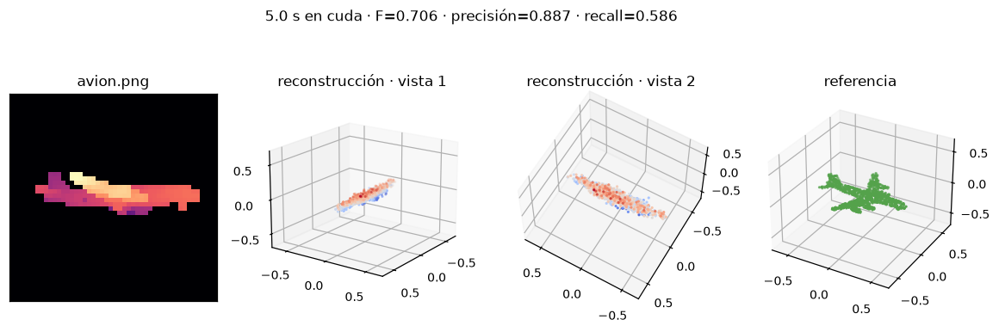

In [21]:
# =============================================================================
# 9.1 · INTERFAZ EN EL NOTEBOOK + EJEMPLOS LISTOS PARA CARGAR
# =============================================================================
def _redimensiona(a, lado):
    '''Redimensionado por vecino más cercano, sin dependencias externas.'''
    h, w = a.shape[:2]
    fi = (np.arange(lado) * h / lado).astype(int).clip(0, h - 1)
    fj = (np.arange(lado) * w / lado).astype(int).clip(0, w - 1)
    return a[fi][:, fj]

def carga_imagen(ruta, lado=None):
    '''Lee .png/.jpg/.bmp/.tif/.npy y devuelve (1,lado,lado) float32 en [0,1].'''
    lado = lado or CFG["img_size"]
    ruta = Path(ruta)
    if ruta.suffix.lower() == ".npy":
        a = np.load(ruta).astype(np.float32)
        if a.ndim == 3 and a.shape[0] in (1, 3): a = a.transpose(1, 2, 0)
    else:
        try:
            from PIL import Image
            a = np.asarray(Image.open(ruta).convert("L"), dtype=np.float32)
        except ImportError:
            if ruta.suffix.lower() != ".png":
                raise RuntimeError(f"{ruta.suffix} necesita pillow: pip install pillow")
            a = plt.imread(ruta).astype(np.float32)
    if a.ndim == 3: a = a[..., :3].mean(-1)          # a escala de grises
    if a.max() > 1.5: a = a / 255.0                  # normalizar si venía en 0-255
    a = _redimensiona(a, lado)
    return np.clip(a, 0, 1)[None].astype(np.float32)

def carga_nube(ruta):
    '''Lee .ply (ASCII), .npy, .csv o .txt y devuelve un array (N,3) float32.'''
    ruta = Path(ruta)
    s = ruta.suffix.lower()
    if s == ".npy":
        p = np.load(ruta)
    elif s == ".ply":
        lineas = ruta.read_text(encoding="utf-8", errors="ignore").splitlines()
        i = next(k for k, l in enumerate(lineas) if l.strip().lower() == "end_header")
        p = np.array([[float(v) for v in l.split()[:3]] for l in lineas[i + 1:] if l.strip()])
    else:
        txt = [l for l in ruta.read_text(encoding="utf-8").splitlines() if l.strip()]
        if any(c.isalpha() for c in txt[0]): txt = txt[1:]        # descartar cabecera
        sep = "," if "," in txt[0] else None
        p = np.array([[float(v) for v in (l.split(sep) if sep else l.split())[:3]] for l in txt])
    return np.asarray(p, dtype=np.float32).reshape(-1, 3)

def guarda_ply(puntos, ruta, color=None):
    pts = np.asarray(puntos, dtype=float)
    with open(ruta, "w", encoding="utf-8") as f:
        f.write("ply\nformat ascii 1.0\n")
        f.write(f"element vertex {len(pts)}\n")
        f.write("property float x\nproperty float y\nproperty float z\n")
        if color is not None:
            f.write("property uchar red\nproperty uchar green\nproperty uchar blue\n")
        f.write("end_header\n")
        for i, p in enumerate(pts):
            if color is None:
                f.write(f"{p[0]:.6f} {p[1]:.6f} {p[2]:.6f}\n")
            else:
                c = color[i]
                f.write(f"{p[0]:.6f} {p[1]:.6f} {p[2]:.6f} {int(c[0])} {int(c[1])} {int(c[2])}\n")
    return ruta

EJ = BASE / "ejemplos"; EJ.mkdir(exist_ok=True)
for i, c in enumerate(CATS):
    k = int(np.where(Y_te == i)[0][0])
    plt.imsave(EJ / f"{c}.png", I_te[k, 0], cmap="gray", vmin=0, vmax=1)
    guarda_ply(P_te[k], EJ / f"{c}.ply")
print("Ejemplos listos para cargar:", ", ".join(sorted(p.name for p in EJ.iterdir())))

def reconstruir(ruta_imagen, ruta_nube=None, omega=None, semilla=7):
    img = carga_imagen(ruta_imagen); gt = carga_nube(ruta_nube) if ruta_nube else None
    t0 = time.time()
    p, _ = muestrea(modelo, torch.from_numpy(img[None]).to(DEVICE), CFG["n_puntos"], DIF,
                    omega=CFG["omega"] if omega is None else float(omega), semilla=int(semilla))
    dt = time.time() - t0; p = p.cpu()[0].numpy()
    fig = plt.figure(figsize=(13, 3.8)); a = fig.add_subplot(1, 4, 1); a.imshow(img[0], cmap="magma")
    a.set_title(Path(ruta_imagen).name); a.grid(False); a.set_xticks([]); a.set_yticks([])
    for k, v in enumerate([(18, 35), (60, 120)]):
        b = fig.add_subplot(1, 4, k + 2, projection="3d"); b.scatter(p[:, 0], p[:, 2], p[:, 1], s=1.2, c=p[:, 1], cmap="coolwarm")
        b.view_init(*v); b.set_title(f"reconstrucción · vista {k+1}"); b.set_xlim(-.7, .7); b.set_ylim(-.7, .7); b.set_zlim(-.7, .7)
    b = fig.add_subplot(1, 4, 4, projection="3d")
    txt = f"{dt:.1f} s en {DEVICE}"
    if gt is not None:
        b.scatter(gt[:, 0], gt[:, 2], gt[:, 1], s=1.2, c="#54a24b"); b.set_title("referencia")
        f, pr, rc = f_score(torch.from_numpy(p)[None], torch.from_numpy(gt)[None], CFG["tau"])
        txt += f" · F={f.item():.3f} · precisión={pr.item():.3f} · recall={rc.item():.3f}"
    else:
        b.set_title("sin referencia")
    b.set_xlim(-.7, .7); b.set_ylim(-.7, .7); b.set_zlim(-.7, .7); fig.suptitle(txt, y=1.02)
    plt.savefig(BASE / "outputs/interfaz/captura_interfaz.png", bbox_inches="tight"); plt.show()
    guarda_ply(p, BASE / "outputs/interfaz/reconstruccion.ply")
    return p

try:
    import ipywidgets as W
    from IPython.display import clear_output
    w_i = W.Dropdown(options=sorted(str(p) for p in EJ.glob("*.png")), description="Imagen:", layout=W.Layout(width="520px"))
    w_r = W.Checkbox(True, description="usar la nube .ply del ejemplo como referencia")
    w_w = W.FloatSlider(float(CFG["omega"]), min=1, max=5, step=.5, description="ω:")
    w_s = W.IntText(7, description="semilla:"); w_b = W.Button(description="Reconstruir en 3D", button_style="primary")
    w_o = W.Output()
    def _go(_):
        with w_o:
            clear_output(wait=True); ref = w_i.value.replace(".png", ".ply") if w_r.value else None
            reconstruir(w_i.value, ref if ref and Path(ref).exists() else None, w_w.value, w_s.value)
    w_b.on_click(_go)
    display(W.VBox([W.HTML("<b>1.</b> Elegir una imagen (o escribir la ruta de una propia) · <b>2.</b> Ajustar ω y semilla · <b>3.</b> Reconstruir"),
                    w_i, w_r, W.HBox([w_w, w_s]), w_b, w_o]))
except ImportError:
    print("ipywidgets no disponible; uso directo:  reconstruir('ejemplos/silla.png', 'ejemplos/silla.ply')")

_ = reconstruir(EJ / f"{CATS[0]}.png", EJ / f"{CATS[0]}.ply")        # demostración automática
tarjeta("9.1 · Interfaz de inferencia",
        "Controles para elegir una imagen, ajustar la guía y la semilla, y ver la reconstrucción con sus métricas. "
        "Se ejecuta una demostración automática con el primer ejemplo.",
        ["Formatos de imagen: .png .jpg .jpeg .bmp .tif .npy · nube de referencia: .ply .npy .csv .txt.",
         f"Ejemplos preparados en <code>ejemplos/</code>: {len(CATS)} imágenes y {len(CATS)} nubes.",
         "Cada reconstrucción se guarda en <code>outputs/interfaz/</code> (captura .png y nube .ply)."],
        ["Cambiar solo la semilla produce otra reconstrucción plausible: el modelo es generativo, no determinista.",
         "Una fotografía real queda fuera de la distribución de entrenamiento: el resultado sería pobre, y es "
         "importante decirlo en la sustentación como limitación."],
        "Se carga una imagen, se pulsa un botón y en segundos aparece la nube 3D.")

In [22]:
# =============================================================================
# 9.2 · APLICACIÓN STREAMLIT (streamlit run streamlit_app/app.py)
# =============================================================================
def _fuente(obj):
    try: return inspect.getsource(obj)
    except Exception: pass
    import re
    for celda in reversed(globals().get("In", [])):
        L = celda.split("\n")
        for i, l in enumerate(L):
            if re.match(rf"^(class|def)\s+{obj.__name__}\b", l):
                s = i
                while s > 0 and L[s - 1].startswith("@"): s -= 1
                j = i + 1
                while j < len(L) and (not L[j].strip() or L[j][:1] in " \t"): j += 1
                return "\n".join(L[s:j]).rstrip()
    raise RuntimeError(obj.__name__)
piezas = [farthest_point_sample, index_points, ball_query, timestep_embedding, CapaSA, CodificadorImagen,
          BloqueTransformer, CapaFP, TrDPNet, Difusion, muestrea, chamfer, f_score,
          _caja, _cilindro, genera_forma, base_camara, renderiza, _redimensiona, carga_imagen, carga_nube]
lib = ("# Librería TrDPNet generada desde el notebook del proyecto.\n"
       "import math, time, numpy as np, torch, torch.nn as nn, torch.nn.functional as F\n"
       "import matplotlib.pyplot as plt\nfrom pathlib import Path\n"
       f"DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')\nDIST_CAM, FOCAL = {DIST_CAM}, {FOCAL}\n"
       f"CFG = {dict(CFG)!r}\n\n" + "\n\n".join(_fuente(p) for p in piezas))
(BASE / "streamlit_app" / "trdpnet_lib.py").write_text(lib, encoding="utf-8")

APP = '''# Interfaz web de TrDPNet · ejecutar:  streamlit run streamlit_app/app.py
from pathlib import Path
import numpy as np, torch, streamlit as st
import trdpnet_lib as T
st.set_page_config(page_title="TrDPNet · imagen a 3D", page_icon="🧊", layout="wide")
RAIZ = Path(__file__).resolve().parent.parent
PESOS = next((p for p in [RAIZ / "weights" / "trdpnet_shapenet.pt",
                          RAIZ / "weights" / "trdpnet_replica.pt"] if p.exists()),
             RAIZ / "weights" / "trdpnet_shapenet.pt")

@st.cache_resource
def cargar():
    ck = torch.load(PESOS, map_location=T.DEVICE, weights_only=False)
    T.CFG = ck["cfg"]; m = T.TrDPNet(ck["cfg"]).to(T.DEVICE); m.load_state_dict(ck["state_dict"]); m.eval()
    c = ck["cfg"]; return m, T.Difusion(c["T"], c["beta_0"], c["beta_T"], c["warmup"], T.DEVICE), c

st.title("🧊 TrDPNet · de una imagen a una nube de puntos 3D")
st.caption("Transformer encoder–decoder + difusión · Li et al., J. Vis. Commun. Image R. 111 (2025)")
if not PESOS.exists():
    st.error(f"No se encontró {PESOS}. Ejecutar antes el notebook."); st.stop()
modelo, dif, cfg = cargar()
with st.sidebar:
    st.header("Parámetros")
    omega = st.slider("Escala de guía ω", 1.0, 5.0, float(cfg["omega"]), .5)
    semilla = st.number_input("Semilla", 0, 9999, 7)
    st.info("Imagen: .png .jpg .jpeg .bmp .tif .npy\\nReferencia (opcional): .ply .npy .csv .txt")
c1, c2 = st.columns([1, 1.6])
with c1:
    st.subheader("1 · Imagen de entrada")
    ejemplos = sorted((RAIZ / "ejemplos").glob("*.png"))
    fuente = st.radio("Origen", ["Ejemplo del proyecto", "Subir archivo"], horizontal=True)
    ref = None
    if fuente == "Ejemplo del proyecto" and ejemplos:
        e = st.selectbox("Ejemplo", ejemplos, format_func=lambda p: p.stem)
        img = T.carga_imagen(e, cfg["img_size"])
        if e.with_suffix(".ply").exists(): ref = T.carga_nube(e.with_suffix(".ply"))
    else:
        up = st.file_uploader("Imagen", type=["png", "jpg", "jpeg", "bmp", "tif", "npy"])
        upr = st.file_uploader("Nube de referencia (opcional)", type=["ply", "npy", "csv", "txt"])
        if up is None: st.stop()
        tmp = RAIZ / "outputs" / ("_subida" + Path(up.name).suffix); tmp.write_bytes(up.getvalue())
        img = T.carga_imagen(tmp, cfg["img_size"])
        if upr is not None:
            tr = RAIZ / "outputs" / ("_ref" + Path(upr.name).suffix); tr.write_bytes(upr.getvalue()); ref = T.carga_nube(tr)
    st.image((img[0] * 255).astype(np.uint8), caption="lo que ve el modelo", width=260)
with c2:
    st.subheader("2 · Reconstrucción 3D")
    if st.button("Reconstruir", type="primary"):
        with st.spinner(f"Muestreando {dif.T} pasos…"):
            p, _ = T.muestrea(modelo, torch.from_numpy(img[None]).to(T.DEVICE), cfg["n_puntos"], dif, omega=omega, semilla=int(semilla))
        p = p.cpu()[0].numpy()
        import plotly.graph_objects as go
        fg = go.Figure(go.Scatter3d(x=p[:, 0], y=p[:, 2], z=p[:, 1], mode="markers", marker=dict(size=2, color=p[:, 1], colorscale="Viridis")))
        fg.update_layout(height=520, scene=dict(aspectmode="data"), margin=dict(l=0, r=0, t=0, b=0))
        st.plotly_chart(fg, use_container_width=True)
        if ref is not None:
            f, pr, rc = T.f_score(torch.from_numpy(p)[None], torch.from_numpy(ref)[None], cfg["tau"])
            a, b, c = st.columns(3); a.metric("F-score", f"{f.item():.3f}"); b.metric("Precisión", f"{pr.item():.3f}"); c.metric("Recall", f"{rc.item():.3f}")
        st.download_button("Descargar nube (.csv)", "x,y,z\\n" + "\\n".join(f"{x:.5f},{y:.5f},{z:.5f}" for x, y, z in p), "nube.csv")
'''
(BASE / "streamlit_app" / "app.py").write_text(APP, encoding="utf-8")
(BASE / "requirements.txt").write_text("numpy\npandas\nmatplotlib\ntorch\npillow\nipywidgets\nplotly\nstreamlit\njupyterlab\n", encoding="utf-8")
import ast; ast.parse(lib); ast.parse(APP)
print("Aplicación Streamlit generada: streamlit_app/app.py + trdpnet_lib.py (sintaxis verificada)")
print("Ejecutar en Anaconda Prompt, desde la carpeta del proyecto:  streamlit run streamlit_app/app.py")

Aplicación Streamlit generada: streamlit_app/app.py + trdpnet_lib.py (sintaxis verificada)
Ejecutar en Anaconda Prompt, desde la carpeta del proyecto:  streamlit run streamlit_app/app.py


# 10 · Cierre: exportar resultados, conclusiones y banco de preguntas

La celda de código escribe `latex/resultados.tex`, un archivo de macros (`\FCond`, `\Ganancia`, …) que usan el informe y la presentación. **Cada vez que se ejecuta el notebook, los documentos LaTeX se actualizan solos** con las cifras reales.

## Conclusiones
- La arquitectura encoder–decoder con atención cruzada **funciona**: la imagen mejora de forma medible la reconstrucción frente al mismo modelo sin ella.
- Q, K y V se derivaron desde los pesos y se **verificaron numéricamente** contra PyTorch.
- La salida del modelo es **ruido**; la geometría emerge al iterar el proceso inverso.

## Limitaciones
1. Escala reducida frente al artículo (dimensión, puntos, pasos de entrenamiento): las cifras absolutas no son comparables con la Tabla 1, solo las tendencias.
2. Una sola vista por modelo en la evaluación y un subconjunto de los modelos disponibles por categoría.
3. Atención cruzada poco selectiva en esta escala: la imagen actúa sobre todo como resumen global.
4. Una fotografía real queda fuera de la distribución de entrenamiento.
5. Inferencia lenta en CPU: T pasos con dos evaluaciones cada uno.

## 🎤 Banco de preguntas probables (cualquier integrante debe poder responderlas)

| Pregunta | Respuesta corta |
|---|---|
| ¿Dónde está el encoder y dónde el decoder? | Encoder: capa SA (nube→tokens) y codificador visual (imagen→tokens). Decoder: capa FP (tokens→ruido por punto). El Transformer fusiona en medio. |
| ¿De dónde salen Q, K y V en la atención cruzada? | Q de los tokens de la nube; K y V de los tokens de la imagen más el token t, cada uno con su matriz aprendida W_q, W_k, W_v. |
| ¿Por qué se divide entre √d_h? | Para que los productos no crezcan con la dimensión y la softmax no se sature. |
| ¿Qué sale del modelo? | El ruido estimado ε̂ (N×3), no coordenadas. |
| ¿Por qué dos evaluaciones por paso? | Guía sin clasificador: una con imagen, otra con el token nulo; se combinan con ω. |
| ¿Qué innova frente a PC²? | La imagen se consulta con atención cruzada en todos los bloques y pasos, en vez de proyectarse solo sobre los puntos visibles. |
| ¿Por qué nubes de puntos son datos secuenciales? | Son secuencias de vectores sin orden; la auto-atención es invariante a permutaciones. |
| ¿Por qué la atención es casi uniforme? | A esta escala la imagen se usa como resumen global (promedio de V); la mejora con/sin imagen demuestra que la información llega. |
| ¿Cómo se sabe que la imagen importa? | Mismo modelo con imagen frente a token nulo: el F-score cambia de forma notable. |
| ¿Qué pasa con una foto real? | Queda fuera de la distribución de entrenamiento; es una limitación declarada. |

latex/resultados.tex: 69 macros · figuras en latex/figuras/: 19


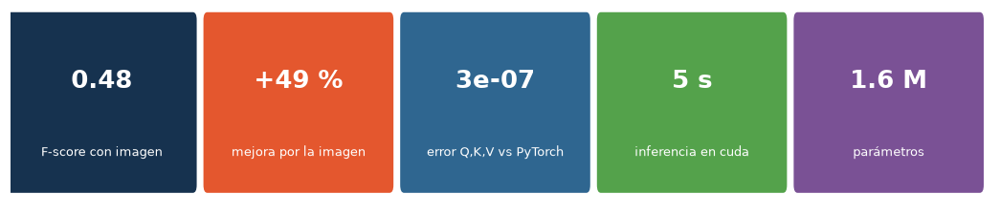

In [24]:
# =============================================================================
# 10 · EXPORTAR RESULTADOS PARA EL INFORME Y LA PRESENTACIÓN
# =============================================================================
mac = {"FCond": f"{F_COND:.3f}", "FUnc": f"{F_UNC:.3f}", "FRnd": f"{F_RND:.3f}", "Ganancia": f"{GAN:.1f}",
       "CDCond": f"{CD_COND:.4f}", "CDUnc": f"{CD_UNC:.4f}", "NPar": f"{n_par:,}".replace(",", "\\,"),
       "PesosMB": f"{mb:.2f}", "ErrQKV": f"{err_salida:.1e}", "OmegaOpt": f"{w_best}", "Entropia": f"{100*ent/ent_max:.0f}",
       "PesoT": f"{peso_t/unif:.1f}", "CorrSil": f"{corr:+.2f}", "TInf": f"{t_inf:.1f}", "Dispositivo": str(DEVICE),
       "NPuntos": str(CFG["n_puntos"]), "Dim": str(CFG["dim"]), "Bloques": str(CFG["depth"]), "Cabezas": str(CFG["heads"]),
       "Dh": str(CFG["dim"] // CFG["heads"]), "Centros": str(CFG["M_centros"]), "Vecinos": str(CFG["K_vecinos"]),
       "Radio": str(CFG["radio"]), "TPasos": str(CFG["T"]), "OmegaCfg": str(CFG["omega"]), "Tau": str(CFG["tau"]),
       "ImgSize": str(CFG["img_size"]), "Parches": str((CFG["img_size"] // CFG["patch"]) ** 2), "Sep": f"{sep:.1f}",
       "RhoImg": f"{rho:.2f}", "Datos": str(CFG.get("datos", "—")), "IoUAlin": f"{100*cohs.mean():.0f}",
       "NPares": str(len(P_te)), "NCats": str(len(CATS)), "CorrPaper": (f"{rho_paper:+.2f}" if comunes else "--"),
       "ModoDatos": str(INFO_DATOS.get("modo", "—")),
       "TEntrenamiento": str(ck.get("meta", {}).get("segundos_entrenamiento", "--")),
       "LossIni": (f"{np.mean(h['loss'][:20]):.3f}" if h.get("loss") else "--"),
       "LossFin": (f"{np.mean(h['loss'][-20:]):.3f}" if h.get("loss") else "--")}
for c in CATS:
    mac["FCat" + c.capitalize()] = f"{R['por_cat'][c][0]:.3f}"; mac["FUncCat" + c.capitalize()] = f"{R['por_cat'][c][1]:.3f}"
for w, f in Wres.items():
    mac["FOmega" + {"1.0": "Uno", "2.0": "Dos", "2.5": "DosMedio", "3.0": "Tres", "3.5": "TresMedio", "5.0": "Cinco"}.get(w, "X")] = f"{f:.3f}"
txt = "% Generado automáticamente por el notebook · " + time.strftime("%Y-%m-%d %H:%M") + "\n" + \
      "\n".join(f"\\renewcommand{{\\{k}}}{{{v}}}" for k, v in mac.items()) + "\n"
(BASE / "latex" / "resultados.tex").write_text(txt, encoding="utf-8")
if (BASE / "outputs/interfaz/captura_interfaz.png").exists():
    shutil.copy(BASE / "outputs/interfaz/captura_interfaz.png", FIG / "captura_interfaz.png")
figs = sorted(p.name for p in FIG.glob("*.png"))
print(f"latex/resultados.tex: {len(mac)} macros · figuras en latex/figuras/: {len(figs)}")

fig, ax = plt.subplots(figsize=(12, 2.4)); ax.axis("off")
cifras = [(f"{F_COND:.2f}", "F-score con imagen"), (f"{GAN:+.0f} %", "mejora por la imagen"),
          (f"{err_salida:.0e}", "error Q,K,V vs PyTorch"), (f"{t_inf:.0f} s", f"inferencia en {DEVICE}"), (f"{n_par/1e6:.1f} M", "parámetros")]
for i, (v, t) in enumerate(cifras):
    ax.add_patch(FancyBboxPatch((i * 2.05, .1), 1.9, .85, boxstyle="round,pad=.04", fc=["#16324f", "#e4572e", "#2f6690", "#54a24b", "#7a5195"][i], ec="none"))
    ax.text(i * 2.05 + .95, .6, v, ha="center", color="white", fontsize=17, weight="bold")
    ax.text(i * 2.05 + .95, .25, t, ha="center", color="white", fontsize=8.5)
ax.set_xlim(0, 10.2); ax.set_ylim(0, 1); guarda("cifras_clave"); plt.show()
tarjeta("10 · El proyecto en cinco cifras",
        "Las cifras clave de esta ejecución, exportadas a <code>latex/resultados.tex</code> para el informe y la presentación.",
        [f"F-score con imagen {F_COND:.3f} frente a {F_UNC:.3f} sin ella ({GAN:+.1f} %).",
         f"Q, K y V verificados contra PyTorch con error {err_salida:.1e}.",
         f"Inferencia de un objeto en {t_inf:.1f} s en {DEVICE}."],
        ["El informe y la presentación leen estas cifras: no hay números copiados a mano.",
         "Antes de sustentar conviene ejecutar el notebook una vez con EVALUACION_COMPLETA = True y luego "
         "presentar con False."],
        "")